# Depth Anything V2 — Monocular Endoscopic Depth Estimation

**Course:** BN5211 Medical Robotics Intelligence

**Dataset:** C3VD  
**Development:** trans_t1_a (61 frames)  
**Test:** trans_t2_b (103 frames)



In [10]:
from google.colab import drive

drive.mount("/content/gdrive")

Mounted at /content/gdrive


In [63]:
import zipfile
from pathlib import Path

zip_path = Path(
    "/content/gdrive/MyDrive/"
    "BN5211_Depth_Estimation/c3vd-main.zip"
)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall("/content")

print(
    "Repository restored:",
    Path("/content/c3vd-main/common.py").exists()
)

Repository restored: True


In [28]:
from pathlib import Path
import yaml

repo = Path("/content/c3vd-main")

config = {
    "data_root": "/content/C3VD",
    "dev_sequence": "trans_t1_a",
    "test_sequence": "trans_t2_b",
    "results_root": "results",
    "device": "auto",
    "seed": 42
}

with open(repo / "config.yaml", "w") as f:
    yaml.safe_dump(config, f)

print("Configuration created successfully!")

Configuration created successfully!


In [67]:
from pathlib import Path
import zipfile

dataset_path = Path(
    "/content/gdrive/MyDrive/BN5211_Depth_Estimation/C3VD"
)

extract_root = Path("/content/C3VD")
extract_root.mkdir(parents=True, exist_ok=True)

for name in ["trans_t1_a", "trans_t2_b"]:

    zip_path = dataset_path / f"{name}.zip"
    extract_path = extract_root / name

    # Skip extraction if dataset already exists
    existing = list(extract_path.rglob("*_color.png"))

    if existing:
        print(f"{name}: Already extracted ({len(existing)} images)")
        continue

    extract_path.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(extract_path)

    print(f"{name}: Extraction completed!")

# Verify using shared configuration
from common import CFG, sequence_dir

dev = sequence_dir(CFG, "dev")
test = sequence_dir(CFG, "test")

print("\nDevelopment frames:", len(list(dev.glob("*_color.png"))))
print("Test frames:", len(list(test.glob("*_color.png"))))

assert len(list(dev.glob("*_color.png"))) == 61
assert len(list(test.glob("*_color.png"))) == 103

print("Dataset setup verified!")

trans_t1_a: Already extracted (61 images)
trans_t2_b: Already extracted (103 images)

Development frames: 61
Test frames: 103
Dataset setup verified!


In [31]:
from pathlib import Path
import shutil

root = Path("/content/C3VD")

for name in ["trans_t1_a", "trans_t2_b"]:
    outer = root / name
    inner = outer / name

    for file in inner.iterdir():
        destination = outer / file.name

        if destination.exists():
            raise FileExistsError(destination)

        shutil.move(str(file), str(destination))

    inner.rmdir()

    count = len(list(outer.glob("*_color.png")))
    print(f"{name}: {count} RGB images")

# Verify using the group's shared loader
from common import CFG, list_frames

print("Development:", len(list_frames(CFG, "dev")))
print("Test:", len(list_frames(CFG, "test")))

trans_t1_a: 61 RGB images
trans_t2_b: 103 RGB images
Development: 61
Test: 103


In [32]:
from common import CFG, list_frames, load_frame, compute_metrics
import numpy as np

dev_paths = list_frames(CFG, "dev")
test_paths = list_frames(CFG, "test")

# Load first development frame
rgb, gt_mm, valid = load_frame(dev_paths[0])

print("RGB shape:", rgb.shape)
print("Depth shape:", gt_mm.shape)
print("Valid pixels:", np.count_nonzero(valid))

# Verify Mask A
print("Minimum valid depth:", gt_mm[valid].min())
print("Maximum valid depth:", gt_mm[valid].max())

print("Development frames:", len(dev_paths))
print("Test frames:", len(test_paths))

RGB shape: (1080, 1350, 3)
Depth shape: (1080, 1350)
Valid pixels: 1327710
Minimum valid depth: 2.464332
Maximum valid depth: 99.998474
Development frames: 61
Test frames: 103


In [24]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


In [12]:
import os

dataset_path = "/content/gdrive/MyDrive/BN5211_Depth_Estimation/C3VD"

print("Dataset folder exists:", os.path.isdir(dataset_path))

if os.path.isdir(dataset_path):
    print("Files:", os.listdir(dataset_path))

Dataset folder exists: True
Files: ['trans_t1_a.zip', 'trans_t2_b.zip']


In [68]:
import torch
import cv2
import numpy
import pandas
import sklearn
import transformers

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("OpenCV:", cv2.__version__)
print("NumPy:", numpy.__version__)
print("Pandas:", pandas.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Transformers:", transformers.__version__)

print("\nEnvironment check completed!")

PyTorch: 2.11.0+cu130
CUDA available: True
OpenCV: 4.14.0
NumPy: 2.1.3
Pandas: 2.2.3
Scikit-learn: 1.6.1
Transformers: 5.21.0

Environment check completed!


In [ ]:
%cd /content

!git clone https://github.com/DepthAnything/Depth-Anything-V2.git

%cd /content/Depth-Anything-V2

/content
Cloning into 'Depth-Anything-V2'...
remote: Enumerating objects: 146, done.
remote: Total 146 (delta 0), reused 0 (delta 0), pack-reused 146 (from 1)
Receiving objects: 100% (146/146), 45.18 MiB | 23.36 MiB/s, done.
Resolving deltas: 100% (45/45), done.
/content/Depth-Anything-V2


In [ ]:
!pip install -q -r requirements.txt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 101.5/101.5 kB 5.8 MB/s eta 0:00:00


In [13]:
import zipfile

for name in ["trans_t1_a", "trans_t2_b"]:
    zip_path = f"{dataset_path}/{name}.zip"
    extract_path = f"/content/C3VD/{name}"

    os.makedirs(extract_path, exist_ok=True)

    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)

    print(f"{name} extracted successfully!")

trans_t1_a extracted successfully!
trans_t2_b extracted successfully!


In [14]:
for name in ["trans_t1_a", "trans_t2_b"]:
    folder = f"/content/C3VD/{name}"

    print(f"\n{name}:")
    print(os.listdir(folder)[:15])


trans_t1_a:
['trans_t1_a']

trans_t2_b:
['trans_t2_b']


In [15]:
import os

for name in ["trans_t1_a", "trans_t2_b"]:
    folder = f"/content/C3VD/{name}/{name}"

    print(f"\n{name}:")
    print(os.listdir(folder)[:20])
    print("Total files:", len(os.listdir(folder)))


trans_t1_a:
['0039_normals.tiff', '0050_color.png', '0039_flow.tiff', '0058_flow.tiff', '0060_depth.tiff', '0013_normals.tiff', '0057_normals.tiff', '0043_normals.tiff', '0010_flow.tiff', '0032_depth.tiff', '0054_color.png', '0026_occlusion.png', '0058_color.png', '0000_color.png', '0046_flow.tiff', '0059_depth.tiff', '0036_color.png', '0024_depth.tiff', '0058_normals.tiff', '0046_depth.tiff']
Total files: 306

trans_t2_b:
['0075_occlusion.png', '0096_flow.tiff', '0039_normals.tiff', '0050_color.png', '0039_flow.tiff', '0086_flow.tiff', '0058_flow.tiff', '0067_color.png', '0060_depth.tiff', '0013_normals.tiff', '0057_normals.tiff', '0043_normals.tiff', '0010_flow.tiff', '0032_depth.tiff', '0087_normals.tiff', '0054_color.png', '0026_occlusion.png', '0058_color.png', '0061_depth.tiff', '0000_color.png']
Total files: 516


RGB shape: (1080, 1350, 3)
Depth shape: (1080, 1350)
Depth datatype: uint16
Depth range: 0 65535


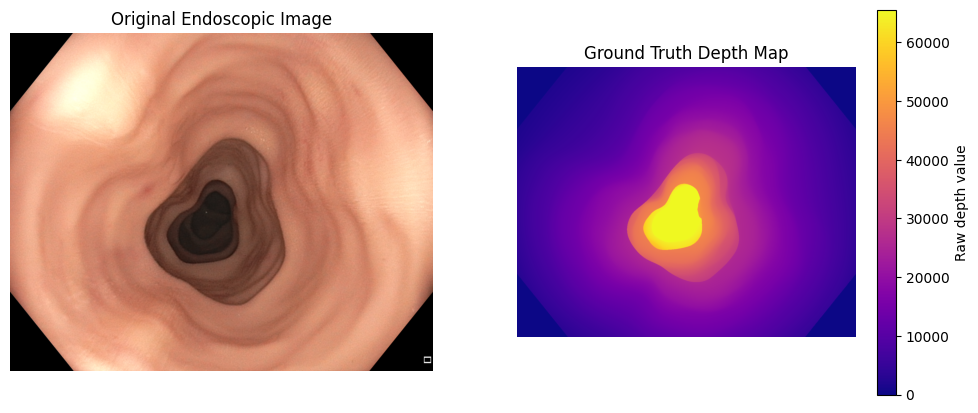

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

folder = "/content/C3VD/trans_t1_a/trans_t1_a"

# Load first RGB image
rgb = cv2.imread(f"{folder}/0001_color.png")
rgb = cv2.cvtColor(rgb, cv2.COLOR_BGR2RGB)

# Load corresponding depth map
depth = cv2.imread(
    f"{folder}/0001_depth.tiff",
    cv2.IMREAD_UNCHANGED
)

print("RGB shape:", rgb.shape)
print("Depth shape:", depth.shape)
print("Depth datatype:", depth.dtype)
print("Depth range:", np.min(depth), np.max(depth))

# Display both
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(rgb)
plt.title("Original Endoscopic Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(depth, cmap="plasma")
plt.title("Ground Truth Depth Map")
plt.colorbar(label="Raw depth value")
plt.axis("off")

plt.show()

Minimum valid depth (mm): 2.4429693
Maximum valid depth (mm): 100.0
Mean valid depth (mm): 25.035471


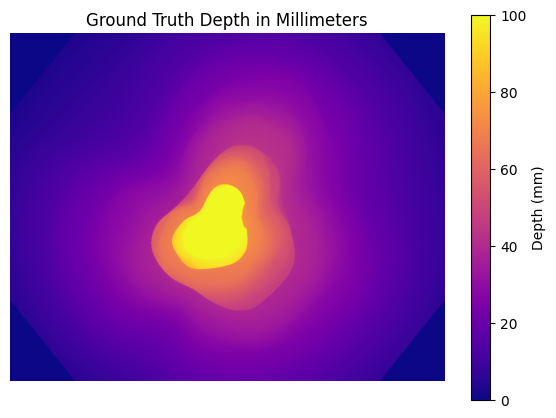

In [ ]:
# Convert 16-bit depth to millimeters
depth_mm = depth.astype(np.float32) / 65535.0 * 100.0

# Exclude zero-depth pixels
valid_mask = depth > 0

print("Minimum valid depth (mm):", depth_mm[valid_mask].min())
print("Maximum valid depth (mm):", depth_mm[valid_mask].max())
print("Mean valid depth (mm):", depth_mm[valid_mask].mean())

plt.figure(figsize=(7, 5))
plt.imshow(depth_mm, cmap="plasma", vmin=0, vmax=100)
plt.colorbar(label="Depth (mm)")
plt.title("Ground Truth Depth in Millimeters")
plt.axis("off")
plt.show()

In [ ]:
import os

print("Current directory:", os.getcwd())
print("Model installed:", os.path.exists("depth_anything_v2/dpt.py"))

Current directory: /content/Depth-Anything-V2
Model installed: True


In [ ]:
%cd /content/Depth-Anything-V2

!mkdir -p checkpoints

!wget -q --show-progress \
https://huggingface.co/depth-anything/Depth-Anything-V2-Small/resolve/main/depth_anything_v2_vits.pth \
-O checkpoints/depth_anything_v2_vits.pth

/content/Depth-Anything-V2
checkpoints/depth_a 100%[===================>]  94.62M   104MB/s    in 0.9s    


In [ ]:
import os

model_path = "checkpoints/depth_anything_v2_vits.pth"

print("Weights downloaded:", os.path.exists(model_path))
print("File size (MB):", round(os.path.getsize(model_path) / 1e6, 2))

Weights downloaded: True
File size (MB): 99.22


In [ ]:
import torch
from depth_anything_v2.dpt import DepthAnythingV2

# Configure Depth Anything V2 Small
model_small = DepthAnythingV2(
    encoder="vits",
    features=64,
    out_channels=[48, 96, 192, 384]
)

# Load pretrained weights
model_small.load_state_dict(
    torch.load(
        "/content/Depth-Anything-V2/checkpoints/depth_anything_v2_vits.pth",
        map_location="cpu",
        weights_only=True
    )
)

# Move model to available device
device = "cuda" if torch.cuda.is_available() else "cpu"

model_small = model_small.to(device).eval()

print("Depth Anything V2 Small loaded successfully!")
print("Running on:", device)

Model loaded successfully!
Running on: cuda
Model: Depth Anything V2 Small


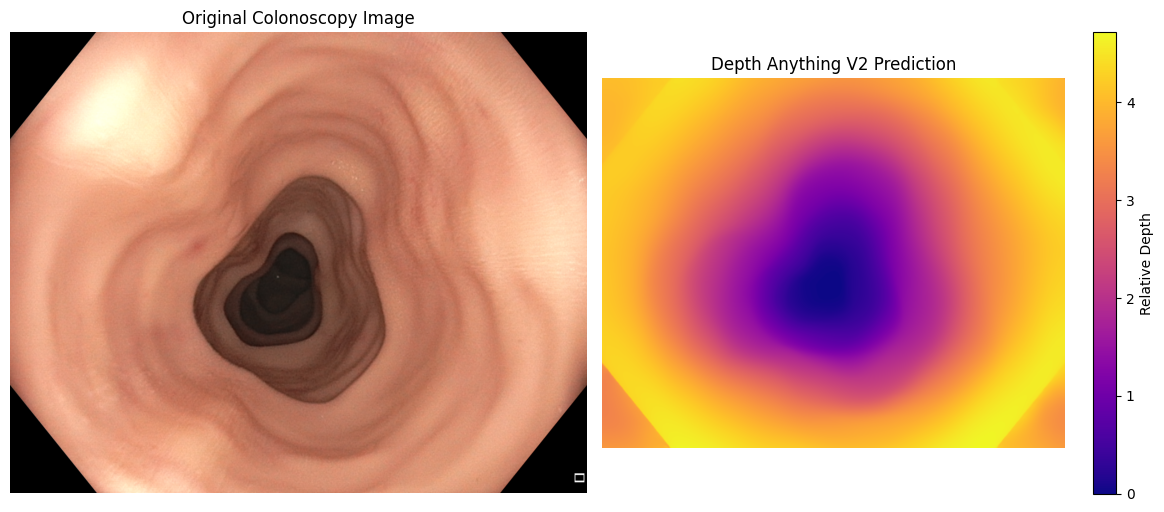

Prediction shape: (1080, 1350)
Minimum prediction: 0.0
Maximum prediction: 4.7171526


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch

from common import CFG, sequence_dir

# Load first C3VD development image
image_path = sequence_dir(CFG, "dev") / "0001_color.png"

image = cv2.imread(str(image_path))

if image is None:
    raise FileNotFoundError(image_path)

# Generate prediction using DAv2 Small
model_small.eval()

with torch.inference_mode():
    predicted_depth = model_small.infer_image(
        image,
        input_size=518
    )

# Convert BGR to RGB
rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Display results
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(rgb_image)
plt.title("Original Colonoscopy Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(predicted_depth, cmap="plasma")
plt.title("DAv2 Small — Relative Depth")
plt.colorbar(label="Relative Depth")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Prediction shape:", predicted_depth.shape)
print("Minimum prediction:", predicted_depth.min())
print("Maximum prediction:", predicted_depth.max())

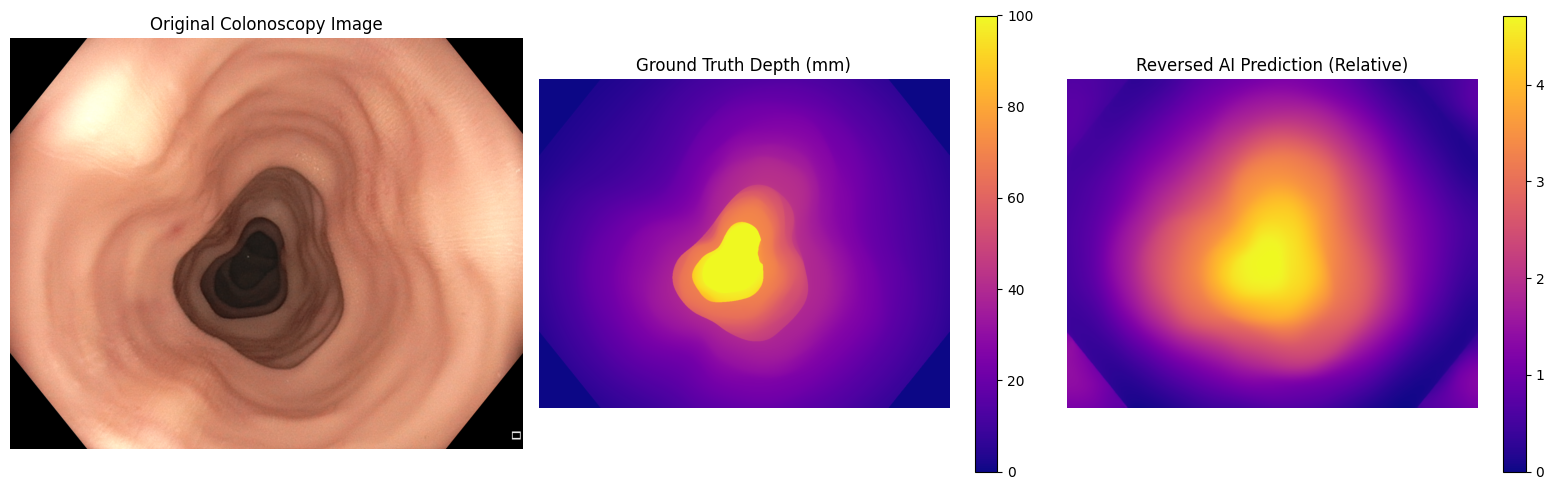

In [ ]:
# Reverse relative-depth direction
reversed_depth = predicted_depth.max() - predicted_depth

# Display comparison
plt.figure(figsize=(16, 5))

plt.subplot(1, 3, 1)
plt.imshow(rgb_image)
plt.title("Original Colonoscopy Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(depth_mm, cmap="plasma")
plt.title("Ground Truth Depth (mm)")
plt.colorbar()
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(reversed_depth, cmap="plasma")
plt.title("Reversed AI Prediction (Relative)")
plt.colorbar()
plt.axis("off")

plt.tight_layout()
plt.show()

Correlation: 0.9091128552648828


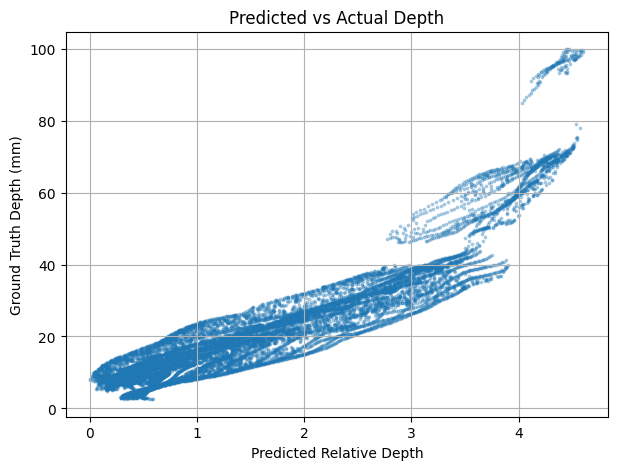

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Select valid ground-truth pixels
valid_mask = (depth > 0) & (depth < 65535)

# Extract corresponding values
gt_values = depth_mm[valid_mask]
pred_values = reversed_depth[valid_mask]

# Calculate correlation
correlation = np.corrcoef(
    gt_values, pred_values
)[0, 1]

print("Correlation:", correlation)

# Plot relationship
plt.figure(figsize=(7, 5))

plt.scatter(
    pred_values[::100],
    gt_values[::100],
    s=3,
    alpha=0.3
)

plt.xlabel("Predicted Relative Depth")
plt.ylabel("Ground Truth Depth (mm)")
plt.title("Predicted vs Actual Depth")
plt.grid(True)
plt.show()

Scale: 13.063408
Offset: 1.3722744


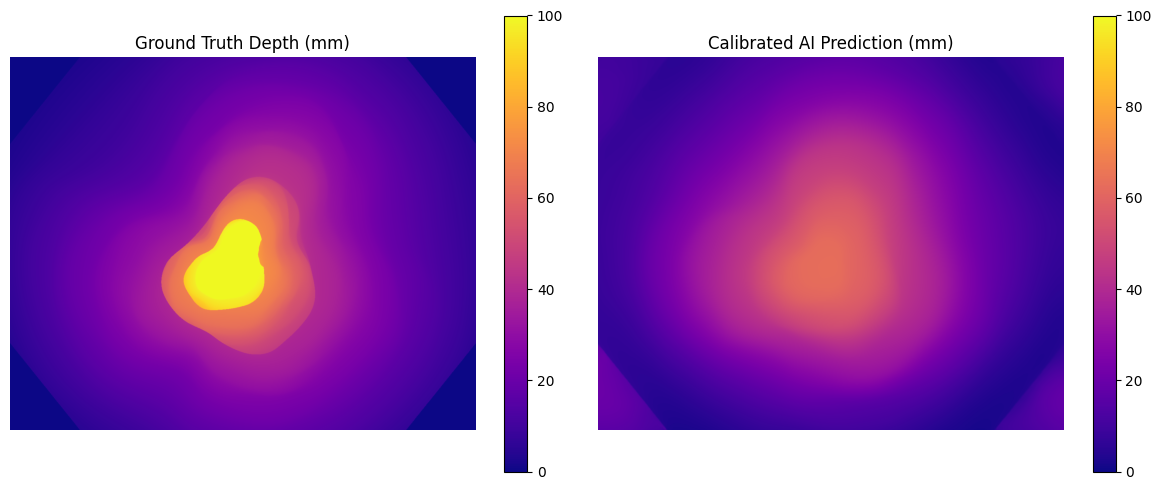

In [ ]:
from sklearn.linear_model import LinearRegression
import numpy as np
import matplotlib.pyplot as plt

# Use valid pixels from the development image
X = pred_values.reshape(-1, 1)
y = gt_values

# Fit linear calibration
calibrator = LinearRegression()
calibrator.fit(X, y)

# Convert relative depth to millimeters
predicted_depth_mm = calibrator.predict(
    reversed_depth.reshape(-1, 1)
).reshape(reversed_depth.shape)

predicted_depth_mm = np.clip(
    predicted_depth_mm, 0, 100
)

print("Scale:", calibrator.coef_[0])
print("Offset:", calibrator.intercept_)

# Visual comparison
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(depth_mm, cmap="plasma", vmin=0, vmax=100)
plt.title("Ground Truth Depth (mm)")
plt.colorbar()
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(predicted_depth_mm, cmap="plasma", vmin=0, vmax=100)
plt.title("Calibrated AI Prediction (mm)")
plt.colorbar()
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import cv2
import numpy as np
import torch

from common import CFG, sequence_dir, stream_results_dir

# Shared paths
dev_folder = sequence_dir(CFG, "dev")

output_folder = (
    stream_results_dir(CFG, "DAv2")
    / "small" / "dev_predictions"
)

output_folder.mkdir(parents=True, exist_ok=True)

image_files = sorted(dev_folder.glob("*_color.png"))

print("Total development images:", len(image_files))

# Check which predictions are missing
missing_files = [
    image_path
    for image_path in image_files
    if not (
        output_folder /
        image_path.name.replace("_color.png", "_pred.npy")
    ).exists()
]

print("Existing predictions:", len(image_files) - len(missing_files))
print("Missing predictions:", len(missing_files))

if missing_files:

    model_small.eval()

    for i, image_path in enumerate(missing_files, 1):

        image = cv2.imread(str(image_path))

        if image is None:
            raise FileNotFoundError(image_path)

        with torch.inference_mode():
            prediction = model_small.infer_image(
                image,
                input_size=518
            )

        output_path = (
            output_folder /
            image_path.name.replace("_color.png", "_pred.npy")
        )

        np.save(
            output_path,
            prediction.astype(np.float32)
        )

        if i % 10 == 0 or i == len(missing_files):
            print(f"Processed {i}/{len(missing_files)}")

else:
    print("All development predictions already available!")

print("Development prediction setup completed!")

Total development images: 61
Processed 10/61 images
Processed 20/61 images
Processed 30/61 images
Processed 40/61 images
Processed 50/61 images
Processed 60/61 images
Processed 61/61 images
All development predictions saved!


In [ ]:
import os
import cv2
import numpy as np
from sklearn.linear_model import LinearRegression

dev_folder = "/content/C3VD/trans_t1_a/trans_t1_a"
output_folder = "/content/C3VD/dev_predictions"

X_all = []
y_all = []

prediction_files = sorted([
    f for f in os.listdir(output_folder)
    if f.endswith("_pred.npy")
])

for filename in prediction_files:

    # Load original AI prediction
    pred = np.load(os.path.join(output_folder, filename))

    # Load corresponding ground-truth depth
    depth_filename = filename.replace("_pred.npy", "_depth.tiff")

    gt_raw = cv2.imread(
        os.path.join(dev_folder, depth_filename),
        cv2.IMREAD_UNCHANGED
    )

    if gt_raw is None:
        raise RuntimeError(f"Cannot load {depth_filename}")

    # Convert ground truth to millimeters
    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

    # Exclude invalid/boundary depth values
    valid = (gt_raw > 0) & (gt_raw < 65535)

    # Use negative prediction because larger model outputs
    # correspond to nearer surfaces in this experiment
    X_all.append((-pred[valid]).reshape(-1, 1))
    y_all.append(gt_mm[valid])

X = np.concatenate(X_all, axis=0)
y = np.concatenate(y_all, axis=0)

# Fit one calibration across all development frames
calibrator = LinearRegression()
calibrator.fit(X, y)

scale = float(calibrator.coef_[0])
offset = float(calibrator.intercept_)

print("Development frames:", len(prediction_files))
print("Total valid pixels:", len(y))
print("Calibration scale:", scale)
print("Calibration offset:", offset)
print("Calibration complete!")

Development frames: 61
Total valid pixels: 80952223
Calibration scale: 13.321044921875
Calibration offset: 64.22636413574219
Calibration complete!


In [ ]:
import os
import cv2
import numpy as np

all_absrel = []
all_squared_errors = []
all_delta = []

for filename in prediction_files:

    pred = np.load(os.path.join(output_folder, filename))

    gt_filename = filename.replace("_pred.npy", "_depth.tiff")
    gt_raw = cv2.imread(
        os.path.join(dev_folder, gt_filename),
        cv2.IMREAD_UNCHANGED
    )

    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

    # Apply fixed calibration
    pred_mm = -scale * pred + offset
    pred_mm = np.clip(pred_mm, 1e-3, 100.0)

    # Valid depth pixels
    valid = (gt_raw > 0) & (gt_raw < 65535)

    gt = gt_mm[valid]
    prediction = pred_mm[valid]

    # Calculate errors
    all_absrel.append(
        np.mean(np.abs(gt - prediction) / gt)
    )

    all_squared_errors.append(
        np.mean((gt - prediction) ** 2)
    )

    ratio = np.maximum(
        gt / prediction,
        prediction / gt
    )

    all_delta.append(
        np.mean(ratio < 1.25)
    )

print("DEVELOPMENT DATASET RESULTS")
print("---------------------------")
print("AbsRel:", np.mean(all_absrel))
print("RMSE (mm):", np.sqrt(np.mean(all_squared_errors)))
print("Delta < 1.25:", np.mean(all_delta))

DEVELOPMENT DATASET RESULTS
---------------------------
AbsRel: 0.31030893
RMSE (mm): 7.2104206
Delta < 1.25: 0.4524115232610192


In [ ]:
import numpy as np

# Calculate median ground-truth depth
# using DEVELOPMENT data only
median_depth = float(np.median(y))

print("Constant median depth (mm):", median_depth)
print("Baseline ready!")

Constant median depth (mm): 17.259479522705078
Baseline ready!


In [ ]:
import cv2
import numpy as np
import torch

from common import CFG, sequence_dir, stream_results_dir

test_folder = sequence_dir(CFG, "test")

test_output = (
    stream_results_dir(CFG, "DAv2")
    / "small" / "test_predictions"
)

test_output.mkdir(parents=True, exist_ok=True)

test_files = sorted(test_folder.glob("*_color.png"))

print("Total test images:", len(test_files))

missing_files = [
    image_path
    for image_path in test_files
    if not (
        test_output /
        image_path.name.replace("_color.png", "_pred.npy")
    ).exists()
]

print("Existing predictions:", len(test_files) - len(missing_files))
print("Missing predictions:", len(missing_files))

if missing_files:

    if "model_small" not in globals():
        raise RuntimeError(
            "Load model_small before generating missing predictions."
        )

    model_small.eval()

    for i, image_path in enumerate(missing_files, 1):

        image = cv2.imread(str(image_path))

        if image is None:
            raise FileNotFoundError(image_path)

        with torch.inference_mode():
            prediction = model_small.infer_image(
                image,
                input_size=518
            )

        output_path = (
            test_output /
            image_path.name.replace("_color.png", "_pred.npy")
        )

        np.save(
            output_path,
            prediction.astype(np.float32)
        )

        if i % 10 == 0 or i == len(missing_files):
            print(f"Processed {i}/{len(missing_files)}")

else:
    print("All local test predictions already available!")

print("Test prediction setup completed!")

Total test images: 103
Processed 10/103
Processed 20/103
Processed 30/103
Processed 40/103
Processed 50/103
Processed 60/103
Processed 70/103
Processed 80/103
Processed 90/103
Processed 100/103
Processed 103/103
All test predictions saved!


In [ ]:
import os
import cv2
import numpy as np

results = {
    "Baseline": {"absrel": [], "sqerr": [], "delta": []},
    "Depth Anything V2": {"absrel": [], "sqerr": [], "delta": []}
}

for filename in sorted(os.listdir(test_output)):
    if not filename.endswith("_pred.npy"):
        continue

    # Load AI prediction
    pred = np.load(os.path.join(test_output, filename))

    # Load ground-truth depth
    gt_filename = filename.replace("_pred.npy", "_depth.tiff")
    gt_raw = cv2.imread(
        os.path.join(test_folder, gt_filename),
        cv2.IMREAD_UNCHANGED
    )

    if gt_raw is None:
        raise RuntimeError(f"Cannot load {gt_filename}")

    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

    # Provisional valid-depth mask
    valid = (gt_raw > 0) & (gt_raw < 65535)

    gt = gt_mm[valid]

    # Model 1: Constant-median baseline
    baseline = np.full_like(gt, median_depth)

    # Model 2: Depth Anything V2
    calibrated = -scale * pred + offset
    calibrated = np.clip(calibrated, 1e-3, 100.0)
    ai = calibrated[valid]

    for name, prediction in [
        ("Baseline", baseline),
        ("Depth Anything V2", ai)
    ]:
        results[name]["absrel"].append(
            np.mean(np.abs(gt - prediction) / gt)
        )

        results[name]["sqerr"].append(
            np.mean((gt - prediction) ** 2)
        )

        ratio = np.maximum(
            gt / prediction,
            prediction / gt
        )

        results[name]["delta"].append(
            np.mean(ratio < 1.25)
        )

print("FINAL TEST COMPARISON")
print("-" * 65)
print(f"{'Model':<22} {'AbsRel':<12} {'RMSE (mm)':<12} {'Delta < 1.25'}")

for name, values in results.items():
    absrel = np.mean(values["absrel"])
    rmse = np.sqrt(np.mean(values["sqerr"]))
    delta = np.mean(values["delta"])

    print(f"{name:<22} {absrel:<12.4f} {rmse:<12.4f} {delta:.4f}")

FINAL TEST COMPARISON
-----------------------------------------------------------------
Model                  AbsRel       RMSE (mm)    Delta < 1.25
Baseline               0.5499       17.7102      0.2752
Depth Anything V2      0.3323       7.1045       0.4587


In [ ]:
import cv2
import numpy as np

folder = "/content/C3VD/trans_t1_a/trans_t1_a"

gt_raw = cv2.imread(
    f"{folder}/0001_depth.tiff",
    cv2.IMREAD_UNCHANGED
)

total = gt_raw.size

zero_pixels = np.sum(gt_raw == 0)
max_pixels = np.sum(gt_raw == 65535)
other_pixels = np.sum((gt_raw > 0) & (gt_raw < 65535))

print("Depth datatype:", gt_raw.dtype)
print("Total pixels:", total)

print("\nPixel distribution:")
print("Zero pixels:", zero_pixels)
print("65535 pixels:", max_pixels)
print("Other pixels:", other_pixels)

print("\nPercentages:")
print("Zero pixels:", round(zero_pixels / total * 100, 2), "%")
print("65535 pixels:", round(max_pixels / total * 100, 2), "%")
print("Other pixels:", round(other_pixels / total * 100, 2), "%")

print("\nDepth percentiles (raw values):")
print(np.percentile(gt_raw, [0, 1, 25, 50, 75, 99, 100]))

Depth datatype: uint16
Total pixels: 1458000

Pixel distribution:
Zero pixels: 102049
65535 pixels: 28974
Other pixels: 1326977

Percentages:
Zero pixels: 7.0 %
65535 pixels: 1.99 %
Other pixels: 91.01 %

Depth percentiles (raw values):
[    0.     0.  6618. 11887. 19491. 65535. 65535.]


In [60]:
from pathlib import Path
import json
import platform
import gc

import numpy as np
import cv2
import pandas as pd

from common import CFG, sequence_dir, stream_results_dir

# ============================================================
# 1. CONFIGURATION
# ============================================================

DEV_DIR = Path(sequence_dir(CFG, "dev"))
TEST_DIR = Path(sequence_dir(CFG, "test"))

RESULTS_ROOT = Path(stream_results_dir(CFG, "DAv2"))

DRIVE_ROOT = Path(
    "/content/gdrive/MyDrive/"
    "BN5211_Depth_Estimation/DepthAnythingV2"
)

OUT = RESULTS_ROOT / "DAv2_GroupProtocol_A"
OUT.mkdir(parents=True, exist_ok=True)

EPS = 1e-3

BINS = np.array(
    [0, 20, 40, 60, 80, 100],
    dtype=np.float64
)

CENTERS = np.array(
    [10, 30, 50, 70],
    dtype=np.float64
)

MODELS = ["Small", "Base", "Large", "Indoor", "Outdoor"]

MODEL_FOLDERS = {
    "Small": "small",
    "Base": "base",
    "Large": "large",
    "Indoor": "indoor",
    "Outdoor": "outdoor"
}

LEGACY_FOLDERS = {
    "Small": DRIVE_ROOT,
    "Base": DRIVE_ROOT / "Base",
    "Large": DRIVE_ROOT / "Large",
    "Indoor": DRIVE_ROOT / "Large_Indoor",
    "Outdoor": DRIVE_ROOT / "Large_Outdoor"
}


# ============================================================
# 2. DATASET LOADING
# ============================================================

def frame_paths(split):
    folder = DEV_DIR if split == "dev" else TEST_DIR
    return sorted(folder.glob("*_color.png"))


def load_gt(color_path):

    color_path = Path(color_path)

    rgb = cv2.imread(
        str(color_path),
        cv2.IMREAD_COLOR
    )

    depth_path = color_path.with_name(
        color_path.name.replace(
            "_color.png", "_depth.tiff"
        )
    )

    raw = cv2.imread(
        str(depth_path),
        cv2.IMREAD_UNCHANGED
    )

    if rgb is None or raw is None:
        raise FileNotFoundError(color_path)

    gt = raw.astype(np.float32) * (100.0 / 65535.0)

    # Group protocol: Mask A
    valid = (
        (raw > 0) &
        (raw < 65535) &
        (rgb.max(axis=2) > 10)
    )

    return rgb, gt, valid


# ============================================================
# 3. PREDICTION PATHS
# ============================================================

def prediction_candidates(model, split):

    folder = MODEL_FOLDERS[model]

    candidates = [
        RESULTS_ROOT / folder / f"{split}_predictions",
        LEGACY_FOLDERS[model] / f"{split}_predictions"
    ]

    # Historical local prediction folders
    local_names = {
        "Small": f"{split}_predictions",
        "Base": f"base_{split}_predictions",
        "Large": f"large_{split}_predictions",
        "Indoor": f"indoor_{split}_predictions",
        "Outdoor": f"outdoor_{split}_predictions"
    }

    candidates.append(
        Path("/content/C3VD") / local_names[model]
    )

    return candidates


def pred_dir(model, split):

    for candidate in prediction_candidates(model, split):

        if candidate.is_dir() and any(
            candidate.glob("*_pred.npy")
        ):
            return candidate

    # Default location for new predictions
    return prediction_candidates(model, split)[0]


def get_pred(model, split, color_path):

    frame = color_path.name.replace("_color.png", "")

    pred_path = pred_dir(model, split) / f"{frame}_pred.npy"

    if not pred_path.exists():
        raise FileNotFoundError(
            f"Missing {model} prediction: {pred_path}"
        )

    prediction = np.squeeze(np.load(pred_path))

    if prediction.ndim != 2:
        raise ValueError(
            f"Invalid prediction shape: {pred_path}"
        )

    rgb = cv2.imread(str(color_path))

    if rgb is None:
        raise FileNotFoundError(color_path)

    if prediction.shape != rgb.shape[:2]:

        prediction = cv2.resize(
            prediction,
            (rgb.shape[1], rgb.shape[0]),
            interpolation=cv2.INTER_CUBIC
        )

    return prediction.astype(np.float32)


# ============================================================
# 4. GENERATE BASE PREDICTIONS IF MISSING
# ============================================================

def ensure_base_predictions():

    missing = []

    for split in ["dev", "test"]:

        folder = pred_dir("Base", split)

        for color_path in frame_paths(split):

            frame = color_path.name.replace("_color.png", "")
            target = folder / f"{frame}_pred.npy"

            if not target.exists():
                missing.append((split, color_path))

    if not missing:
        print("Base predictions already available.")
        return

    import torch
    import torch.nn.functional as F

    from PIL import Image
    from transformers import (
        AutoImageProcessor,
        AutoModelForDepthEstimation
    )

    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

    model_id = "depth-anything/Depth-Anything-V2-Base-hf"

    print("Loading Base model:", model_id)

    processor = AutoImageProcessor.from_pretrained(model_id)

    model = AutoModelForDepthEstimation.from_pretrained(
        model_id
    ).to(device).eval()

    for split, color_path in missing:

        frame = color_path.name.replace("_color.png", "")

        folder = pred_dir("Base", split)
        folder.mkdir(parents=True, exist_ok=True)

        bgr = cv2.imread(str(color_path))

        if bgr is None:
            raise FileNotFoundError(color_path)

        rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

        inputs = processor(
            images=Image.fromarray(rgb),
            return_tensors="pt"
        ).to(device)

        with torch.inference_mode():

            raw = model(**inputs).predicted_depth

            raw = F.interpolate(
                raw.unsqueeze(1),
                size=rgb.shape[:2],
                mode="bicubic",
                align_corners=False
            ).squeeze().cpu().numpy()

        np.save(
            folder / f"{frame}_pred.npy",
            raw.astype(np.float32)
        )

    del model
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    print("Base predictions ready.")


# ============================================================
# 5. DEVELOPMENT-ONLY LINEAR CALIBRATION
# ============================================================

def fit_linear(model):

    n = 0
    sx = sy = sxx = sxy = 0.0

    for color_path in frame_paths("dev"):

        _, gt, valid = load_gt(color_path)

        raw = get_pred(model, "dev", color_path)

        if model in ["Indoor", "Outdoor"]:
            x = (raw * 1000.0)[valid]
        else:
            x = (-raw)[valid]

        x = x.astype(np.float64)
        y = gt[valid].astype(np.float64)

        n += len(x)

        sx += x.sum()
        sy += y.sum()

        sxx += np.dot(x, x)
        sxy += np.dot(x, y)

    if n == 0:
        raise ValueError("No valid development pixels.")

    denominator = sxx - sx * sx / n

    if abs(denominator) < 1e-10:
        raise ValueError("Degenerate calibration.")

    scale = (sxy - sx * sy / n) / denominator

    offset = (sy - scale * sx) / n

    return float(scale), float(offset), int(n)


def calibrated(model, raw, scale, offset):

    if model in ["Indoor", "Outdoor"]:
        x = raw * 1000.0
    else:
        x = -raw

    return np.clip(
        scale * x + offset,
        EPS,
        100.0
    )


# ============================================================
# 6. SMALL MODEL SMOOTH CORRECTION
# ============================================================

def fit_smooth(scale, offset):

    sums = np.zeros(5, dtype=np.float64)
    counts = np.zeros(5, dtype=np.int64)

    for color_path in frame_paths("dev"):

        _, gt, valid = load_gt(color_path)

        raw = get_pred("Small", "dev", color_path)

        linear = calibrated(
            "Small", raw, scale, offset
        )

        idx = np.searchsorted(
            BINS,
            linear,
            side="right"
        ) - 1

        idx = np.clip(idx, 0, 4)

        for k in range(5):

            mask = valid & (idx == k)

            sums[k] += np.sum(
                gt[mask] - linear[mask],
                dtype=np.float64
            )

            counts[k] += np.count_nonzero(mask)

    corrections = np.divide(
        sums,
        counts,
        out=np.zeros_like(sums),
        where=counts > 0
    )

    return corrections, counts


# ============================================================
# 7. EVALUATION METRICS
# ============================================================

def calculate_metrics(gt, prediction, valid):

    g = gt[valid].astype(np.float64)

    p = np.clip(
        prediction[valid].astype(np.float64),
        EPS,
        100.0
    )

    error = p - g

    return {
        "absrel": float(
            np.mean(np.abs(error) / g)
        ),
        "mae": float(
            np.mean(np.abs(error))
        ),
        "mse": float(
            np.mean(error ** 2)
        ),
        "delta1": float(
            np.mean(
                np.maximum(p / g, g / p) < 1.25
            )
        ),
        "pixels": int(len(g))
    }


def evaluate(
    model,
    split,
    scale,
    offset,
    corrections=None,
    oracle=False
):

    records = []

    for color_path in frame_paths(split):

        _, gt, valid = load_gt(color_path)

        raw = get_pred(model, split, color_path)

        prediction = calibrated(
            model,
            raw,
            scale,
            offset
        )

        # Smooth correction
        if corrections is not None:

            prediction = np.clip(
                prediction + np.interp(
                    prediction,
                    CENTERS,
                    corrections[:4]
                ),
                EPS,
                100.0
            )

        # Oracle uses test ground truth
        if oracle:

            gt_median = np.median(gt[valid])
            pred_median = np.median(prediction[valid])

            prediction = np.clip(
                prediction * (
                    gt_median / max(pred_median, EPS)
                ),
                EPS,
                100.0
            )

        metrics = calculate_metrics(
            gt,
            prediction,
            valid
        )

        metrics["frame"] = color_path.name.replace(
            "_color.png", ""
        )

        records.append(metrics)

    df = pd.DataFrame(records)

    summary = {
        "absrel": float(df["absrel"].mean()),
        "mae": float(df["mae"].mean()),
        "rmse": float(np.sqrt(df["mse"].mean())),
        "delta1": float(df["delta1"].mean()),
        "n_frames": len(df),
        "n_pixels": int(df["pixels"].sum())
    }

    return df, summary


# ============================================================
# 8. RUN ALL MODEL COMPARISONS
# ============================================================

def main():

    assert len(frame_paths("dev")) == 61
    assert len(frame_paths("test")) == 103

    ensure_base_predictions()

    summary = []
    parameters = {}

    for model in MODELS:

        print("\nEvaluating:", model)

        scale, offset, n = fit_linear(model)

        parameters[model] = {
            "scale": scale,
            "offset": offset,
            "dev_valid_pixels": n,
            "raw_units": (
                "meters"
                if model in ["Indoor", "Outdoor"]
                else "relative"
            )
        }

        df, result = evaluate(
            model,
            "test",
            scale,
            offset
        )

        df.to_csv(
            OUT / f"{model.lower()}_linear_maskA_test_per_frame.csv",
            index=False
        )

        summary.append({
            "method": f"DAv2 {model} + global linear",
            "mask": "A",
            "aggregation": "frame mean, sqrt(mean MSE)",
            "split": "test",
            "fit_on": "dev",
            **result
        })

        print(model, result)

        if model == "Small":

            # Smooth correction
            corrections, counts = fit_smooth(
                scale,
                offset
            )

            parameters["Small_smooth"] = {
                "bin_centers_mm": CENTERS.tolist(),
                "corrections_mm": corrections.tolist(),
                "bin_counts": counts.tolist(),
                "note": (
                    "Only first four bins are interpolated; "
                    "the 80–100 mm bin has no fitted pixels "
                    "when its count is zero."
                )
            }

            df, smooth_result = evaluate(
                model,
                "test",
                scale,
                offset,
                corrections=corrections
            )

            df.to_csv(
                OUT / "small_smooth_maskA_test_per_frame.csv",
                index=False
            )

            summary.append({
                "method": "DAv2 Small + smooth correction",
                "mask": "A",
                "aggregation": "frame mean, sqrt(mean MSE)",
                "split": "test",
                "fit_on": "dev",
                **smooth_result
            })

            print("Small smooth:", smooth_result)

            # Oracle: not deployable
            df, oracle_result = evaluate(
                model,
                "test",
                scale,
                offset,
                oracle=True
            )

            df.to_csv(
                OUT / "small_median_oracle_maskA_test_per_frame.csv",
                index=False
            )

            summary.append({
                "method": "DAv2 Small + per-image GT median ORACLE",
                "mask": "A",
                "aggregation": "frame mean, sqrt(mean MSE)",
                "split": "test",
                "fit_on": "TEST GT (ORACLE)",
                **oracle_result
            })

            print("Small oracle:", oracle_result)

    # Save summary
    summary_df = pd.DataFrame(summary)

    summary_df.to_csv(
        OUT / "dav2_all_variants_maskA_frame_mean_test.csv",
        index=False
    )

    # Save calibration parameters
    with open(
        OUT / "calibration_parameters_maskA.json",
        "w"
    ) as f:
        json.dump(parameters, f, indent=2)

    # Save environment information
    import torch
    import transformers

    run_info = {
        "python": platform.python_version(),
        "torch": torch.__version__,
        "transformers": transformers.__version__,
        "numpy": np.__version__,
        "opencv": cv2.__version__,
        "mask": "A: raw>0 & raw<65535 & RGB max>10",
        "aggregation": (
            "mean frame AbsRel/MAE/Delta; "
            "sqrt(mean frame MSE)"
        ),
        "dev": "trans_t1_a",
        "test": "trans_t2_b",
        "note": (
            "Predictions may originate from different "
            "preprocessing pipelines. Verify checkpoints "
            "and preprocessing before interpreting "
            "cross-model comparisons."
        )
    }

    with open(OUT / "run_info.json", "w") as f:
        json.dump(run_info, f, indent=2)

    print("\nFINAL RESULTS — MASK A")
    print("-" * 80)

    print(
        summary_df[
            ["method", "absrel", "rmse", "mae", "delta1"]
        ].to_string(index=False)
    )

    print("\nResults saved to:", OUT)


# ============================================================
# 9. EXECUTE
# ============================================================

if __name__ == "__main__":
    main()

Base predictions already available.

Evaluating: Small
Small {'absrel': 0.3322994482224376, 'mae': 5.330451638531677, 'rmse': 7.10444606577203, 'delta1': 0.45873106404464437, 'n_frames': 103, 'n_pixels': 136648666}
Small smooth: {'absrel': 0.28052515114812326, 'mae': 4.409883934945352, 'rmse': 5.595781375673298, 'delta1': 0.5349643815520103, 'n_frames': 103, 'n_pixels': 136648666}
Small oracle: {'absrel': 0.32573148869531715, 'mae': 5.8632849561266225, 'rmse': 8.38663929387746, 'delta1': 0.48052765356883126, 'n_frames': 103, 'n_pixels': 136648666}

Evaluating: Base
Base {'absrel': 0.2950269231822919, 'mae': 4.903627584499147, 'rmse': 6.633929105753369, 'delta1': 0.5206233045023415, 'n_frames': 103, 'n_pixels': 136648666}

Evaluating: Large
Large {'absrel': 0.25972112599305647, 'mae': 4.368526978489362, 'rmse': 6.151678509906439, 'delta1': 0.6001260235884727, 'n_frames': 103, 'n_pixels': 136648666}

Evaluating: Indoor
Indoor {'absrel': 0.26859232850230774, 'mae': 5.549873225115585, 'rms

In [21]:
import os
import pandas as pd

folder = (
    "/content/gdrive/MyDrive/"
    "BN5211_Depth_Estimation/DepthAnythingV2/"
    "DAv2_GroupProtocol_A"
)

print("Saved files:")
for f in os.listdir(folder):
    print(f)

Saved files:
small_linear_maskA_test_per_frame.csv
small_smooth_maskA_test_per_frame.csv
small_median_oracle_maskA_test_per_frame.csv
base_linear_maskA_test_per_frame.csv
large_linear_maskA_test_per_frame.csv
indoor_linear_maskA_test_per_frame.csv
outdoor_linear_maskA_test_per_frame.csv
dav2_all_variants_maskA_frame_mean_test.csv
calibration_parameters_maskA.json
run_info.json


In [22]:
import os
import numpy as np
import pandas as pd

folder = (
    "/content/gdrive/MyDrive/"
    "BN5211_Depth_Estimation/DepthAnythingV2/"
    "DAv2_GroupProtocol_A"
)

files = [
    "small_linear_maskA_test_per_frame.csv",
    "small_smooth_maskA_test_per_frame.csv",
    "base_linear_maskA_test_per_frame.csv",
    "large_linear_maskA_test_per_frame.csv",
    "indoor_linear_maskA_test_per_frame.csv",
    "outdoor_linear_maskA_test_per_frame.csv"
]

for filename in files:
    df = pd.read_csv(os.path.join(folder, filename))

    print("\nFile:", filename)
    print("Columns:", df.columns.tolist())

    # Group protocol: frame averages
    absrel = df["absrel"].mean()
    mae = df["mae"].mean()
    delta = df["delta1"].mean()

    # RMSE = sqrt(mean of frame MSE)
    if "mse" in df.columns:
        rmse = np.sqrt(df["mse"].mean())
    else:
        rmse = np.sqrt(np.mean(df["rmse"] ** 2))

    print(
        f"AbsRel={absrel:.6f} | "
        f"MAE={mae:.6f} | "
        f"RMSE={rmse:.6f} | "
        f"Delta={delta:.6f}"
    )


File: small_linear_maskA_test_per_frame.csv
Columns: ['absrel', 'mae', 'mse', 'delta1', 'pixels', 'frame']
AbsRel=0.332299 | MAE=5.330452 | RMSE=7.104446 | Delta=0.458731

File: small_smooth_maskA_test_per_frame.csv
Columns: ['absrel', 'mae', 'mse', 'delta1', 'pixels', 'frame']
AbsRel=0.280525 | MAE=4.409884 | RMSE=5.595781 | Delta=0.534964

File: base_linear_maskA_test_per_frame.csv
Columns: ['absrel', 'mae', 'mse', 'delta1', 'pixels', 'frame']
AbsRel=0.295027 | MAE=4.903628 | RMSE=6.633929 | Delta=0.520623

File: large_linear_maskA_test_per_frame.csv
Columns: ['absrel', 'mae', 'mse', 'delta1', 'pixels', 'frame']
AbsRel=0.259721 | MAE=4.368527 | RMSE=6.151679 | Delta=0.600126

File: indoor_linear_maskA_test_per_frame.csv
Columns: ['absrel', 'mae', 'mse', 'delta1', 'pixels', 'frame']
AbsRel=0.268592 | MAE=5.549873 | RMSE=7.714805 | Delta=0.453051

File: outdoor_linear_maskA_test_per_frame.csv
Columns: ['absrel', 'mae', 'mse', 'delta1', 'pixels', 'frame']
AbsRel=0.298804 | MAE=5.479325

In [16]:
import os

print("C3VD exists:", os.path.exists("/content/C3VD"))

for root, dirs, files in os.walk("/content/C3VD"):
    if any(f.endswith("_depth.tiff") for f in files):
        print("Dataset location:", root)

C3VD exists: True
Dataset location: /content/C3VD/trans_t2_b/trans_t2_b
Dataset location: /content/C3VD/trans_t1_a/trans_t1_a


In [17]:
from common import CFG, sequence_dir

test_folder = str(sequence_dir(CFG, "test"))
dev_folder = str(sequence_dir(CFG, "dev"))

import os
print("Test folder exists:", os.path.isdir(test_folder))
print("Development folder exists:", os.path.isdir(dev_folder))

print("Test depth files:", len([
    f for f in os.listdir(test_folder)
    if f.endswith("_depth.tiff")
]))

print("Development depth files:", len([
    f for f in os.listdir(dev_folder)
    if f.endswith("_depth.tiff")
]))

Test folder exists: True
Development folder exists: True
Test depth files: 103
Development depth files: 61


In [11]:
import os

for root, dirs, files in os.walk("/content/C3VD"):
    depth_files = [
        f for f in files
        if f.endswith("_depth.tiff")
    ]

    if depth_files:
        print("Folder:", root)
        print("Depth files:", len(depth_files))
        print("Example:", depth_files[0])

Folder: /content/C3VD/trans_t2_b/trans_t2_b
Depth files: 103
Example: 0029_depth.tiff
Folder: /content/C3VD/trans_t1_a/trans_t1_a
Depth files: 61
Example: 0029_depth.tiff


In [9]:
import os

for root, dirs, files in os.walk("/content/C3VD"):
    depth_files = [
        f for f in files
        if f.endswith("_depth.tiff")
    ]

    if depth_files:
        print("Folder:", root)
        print("Number of depth files:", len(depth_files))
        print("Example:", depth_files[0])
        print()

Folder: /content/C3VD/trans_t2_b/trans_t2_b
Number of depth files: 103
Example: 0029_depth.tiff

Folder: /content/C3VD/trans_t1_a/trans_t1_a
Number of depth files: 61
Example: 0029_depth.tiff



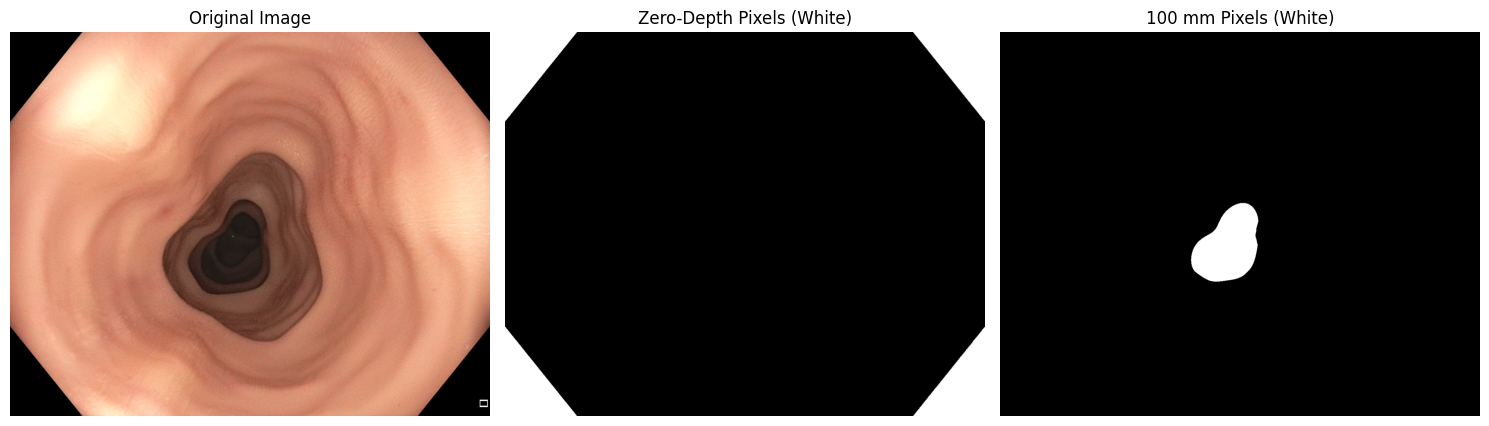

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from common import CFG, sequence_dir

folder = str(sequence_dir(CFG, "dev"))
rgb = cv2.cvtColor(
    cv2.imread(f"{folder}/0001_color.png"),
    cv2.COLOR_BGR2RGB
)

gt_raw = cv2.imread(
    f"{folder}/0001_depth.tiff",
    cv2.IMREAD_UNCHANGED
)

zero_mask = gt_raw == 0
max_mask = gt_raw == 65535

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(zero_mask, cmap="gray")
plt.title("Zero-Depth Pixels (White)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(max_mask, cmap="gray")
plt.title("100 mm Pixels (White)")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import os
import cv2
import numpy as np
from sklearn.linear_model import LinearRegression

X_all = []
y_all = []

for filename in prediction_files:
    pred = np.load(os.path.join(output_folder, filename))

    gt_filename = filename.replace("_pred.npy", "_depth.tiff")

    gt_raw = cv2.imread(
        os.path.join(dev_folder, gt_filename),
        cv2.IMREAD_UNCHANGED
    )

    rgb = cv2.imread(
        os.path.join(
            dev_folder,
            filename.replace("_pred.npy", "_color.png")
        )
    )

    if gt_raw is None or rgb is None:
        raise FileNotFoundError(f"Missing image for {filename}")

    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

    # Group evaluation protocol: Mask A
    valid = (
        (gt_raw > 0) &
        (gt_raw < 65535) &
        (rgb.max(axis=2) > 10)
    )

    X_all.append((-pred[valid]).reshape(-1, 1))
    y_all.append(gt_mm[valid])

X = np.concatenate(X_all)
y = np.concatenate(y_all)

calibrator = LinearRegression()
calibrator.fit(X, y)

scale = float(calibrator.coef_[0])
offset = float(calibrator.intercept_)
median_depth = float(np.median(y))

print("Updated scale:", scale)
print("Updated offset:", offset)
print("Updated median baseline (mm):", median_depth)
print("Total valid development pixels:", len(y))

Updated scale: 14.802687644958496
Updated offset: 69.5309829711914
Updated median baseline (mm): 17.582971572875977
Total valid development pixels: 82713011


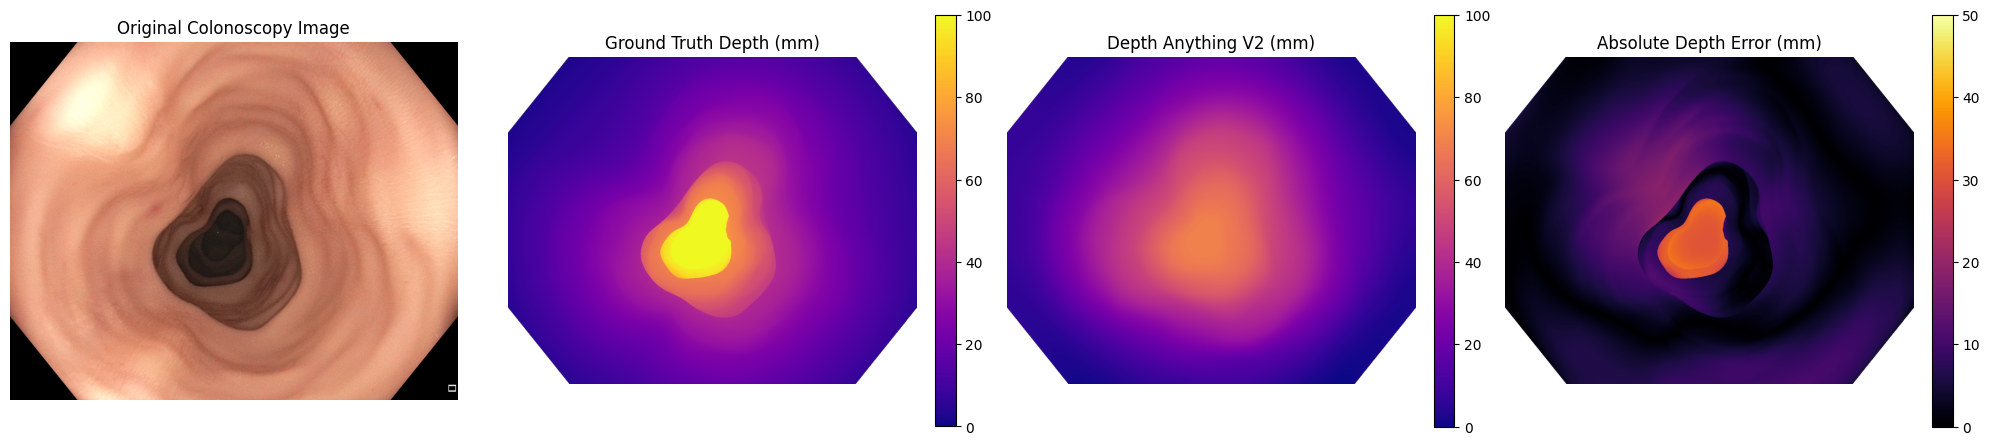

Figure saved to: /content/drive/MyDrive/BN5211_Depth_Estimation/DepthAnythingV2/depth_comparison.png
Mean Absolute Error (mm): 6.204653


In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from common import CFG, sequence_dir, stream_results_dir

frame = "0001"

# Paths from shared configuration
folder = str(sequence_dir(CFG, "dev"))
pred_folder = str(
    stream_results_dir(CFG, "DAv2") / "small" / "dev_predictions"
)

# Load RGB and ground truth
rgb_bgr = cv2.imread(f"{folder}/{frame}_color.png")
gt_raw = cv2.imread(
    f"{folder}/{frame}_depth.tiff",
    cv2.IMREAD_UNCHANGED
)

if rgb_bgr is None or gt_raw is None:
    raise FileNotFoundError(f"Missing development frame {frame}")

rgb = cv2.cvtColor(rgb_bgr, cv2.COLOR_BGR2RGB)
gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

# Load saved prediction
pred = np.load(f"{pred_folder}/{frame}_pred.npy")

# Existing development-fitted calibration
pred_mm = np.clip(
    -scale * pred + offset,
    1e-3, 100.0
)

# Group protocol: Mask A
valid = (
    (gt_raw > 0) &
    (gt_raw < 65535) &
    (rgb.max(axis=2) > 10)
)

# Absolute error
error = np.abs(gt_mm - pred_mm)

gt_display = np.where(valid, gt_mm, np.nan)
pred_display = np.where(valid, pred_mm, np.nan)
error_display = np.where(valid, error, np.nan)

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].imshow(rgb)
axes[0].set_title("Original Colonoscopy Image")

im1 = axes[1].imshow(
    gt_display, cmap="plasma", vmin=0, vmax=100
)
axes[1].set_title("Ground Truth Depth (mm)")

im2 = axes[2].imshow(
    pred_display, cmap="plasma", vmin=0, vmax=100
)
axes[2].set_title("DAv2 Small + Linear (mm)")

im3 = axes[3].imshow(
    error_display, cmap="inferno", vmin=0, vmax=50
)
axes[3].set_title("Absolute Depth Error (mm)")

for ax in axes:
    ax.axis("off")

fig.colorbar(im1, ax=axes[1])
fig.colorbar(im2, ax=axes[2])
fig.colorbar(im3, ax=axes[3])

plt.tight_layout()

# Save to the configured results folder
save_dir = stream_results_dir(CFG, "DAv2")
save_path = save_dir / "small_linear_dev_comparison.png"

plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved to:", save_path)
print("MAE (mm):", np.mean(error[valid]))

0–20 mm: MAE = 4.828 mm, Pixels = 47315777
20–40 mm: MAE = 7.096 mm, Pixels = 21834912
40–60 mm: MAE = 5.265 mm, Pixels = 7681999
60–100 mm: MAE = 19.431 mm, Pixels = 5880323


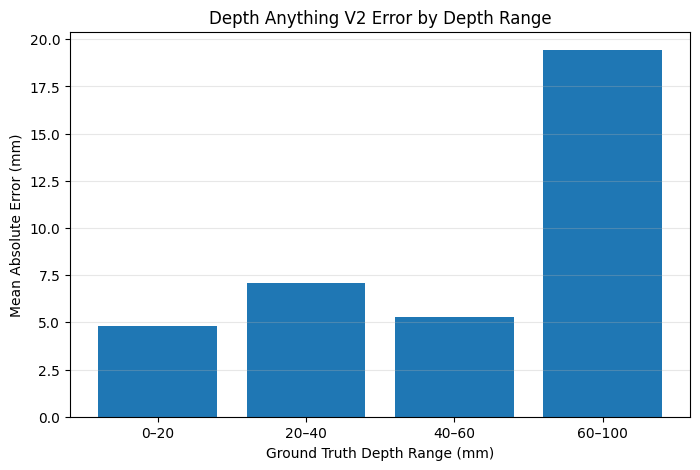

In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

depth_ranges = [(0, 20), (20, 40), (40, 60), (60, 100)]

error_sums = np.zeros(4, dtype=np.float64)
pixel_counts = np.zeros(4, dtype=np.int64)

for filename in prediction_files:

    pred = np.load(os.path.join(output_folder, filename))

    gt_filename = filename.replace("_pred.npy", "_depth.tiff")

    gt_raw = cv2.imread(
        os.path.join(dev_folder, gt_filename),
        cv2.IMREAD_UNCHANGED
    )

    rgb = cv2.imread(
        os.path.join(
            dev_folder,
            filename.replace("_pred.npy", "_color.png")
        )
    )

    if gt_raw is None or rgb is None:
        raise FileNotFoundError(filename)

    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

    pred_mm = np.clip(
        -scale * pred + offset,
        1e-3,
        100.0
    )

    # Group protocol: Mask A
    valid = (
        (gt_raw > 0) &
        (gt_raw < 65535) &
        (rgb.max(axis=2) > 10)
    )

    error = np.abs(gt_mm - pred_mm)

    for i, (low, high) in enumerate(depth_ranges):

        if high == 100:
            mask = valid & (gt_mm >= low) & (gt_mm <= high)
        else:
            mask = valid & (gt_mm >= low) & (gt_mm < high)

        error_sums[i] += np.sum(error[mask], dtype=np.float64)
        pixel_counts[i] += np.count_nonzero(mask)

mae_by_range = error_sums / np.maximum(pixel_counts, 1)

labels = ["0–20", "20–40", "40–60", "60–100"]

for label, mae, count in zip(labels, mae_by_range, pixel_counts):
    print(f"{label} mm: MAE = {mae:.3f} mm, Pixels = {count}")

plt.figure(figsize=(8, 5))
plt.bar(labels, mae_by_range)
plt.xlabel("Ground Truth Depth Range (mm)")
plt.ylabel("Mean Absolute Error (mm)")
plt.title("Depth Anything V2 Error by Depth Range — Mask A")
plt.grid(axis="y", alpha=0.3)
plt.show()

In [ ]:
import numpy as np
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

# X and y were created from all development frames in Step 27
# X = negative raw model predictions
# y = ground-truth depth in millimeters

# Use a sample to reduce computation
rng = np.random.default_rng(42)
sample_size = min(500000, len(y))

indices = rng.choice(
    len(y),
    size=sample_size,
    replace=False
)

X_sample = X[indices]
y_sample = y[indices]

# Create second-degree polynomial features
poly = PolynomialFeatures(
    degree=2,
    include_bias=False
)

X_poly = poly.fit_transform(X_sample)

# Train nonlinear calibration
poly_model = LinearRegression()
poly_model.fit(X_poly, y_sample)

print("Polynomial coefficients:", poly_model.coef_)
print("Intercept:", poly_model.intercept_)
print("Polynomial calibration trained successfully!")

Polynomial coefficients: [ 0.44736296 -2.4325354 ]
Intercept: 52.119026
Polynomial calibration trained successfully!


In [ ]:
import os
import cv2
import numpy as np

comparison = {
    "Linear": {"absrel": [], "sqerr": [], "delta": []},
    "Polynomial": {"absrel": [], "sqerr": [], "delta": []}
}

for filename in prediction_files:

    # Load saved prediction
    pred = np.load(os.path.join(output_folder, filename))

    # Load ground-truth depth
    gt_filename = filename.replace("_pred.npy", "_depth.tiff")
    gt_raw = cv2.imread(
        os.path.join(dev_folder, gt_filename),
        cv2.IMREAD_UNCHANGED
    )

    rgb = cv2.imread(
        os.path.join(
            dev_folder,
            filename.replace("_pred.npy", "_color.png")
        )
    )

    if gt_raw is None or rgb is None:
        raise FileNotFoundError(filename)

    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

    # Group protocol: Mask A
    valid = (
        (gt_raw > 0) &
        (gt_raw < 65535) &
        (rgb.max(axis=2) > 10)
    )

    # Original linear calibration
    linear_depth = np.clip(
        -scale * pred + offset,
        1e-3, 100.0
    )

    # New polynomial calibration
    # Coefficients correspond to P and P^2, where P = -pred
    p = -pred
    a, b = poly_model.coef_

    polynomial_depth = np.clip(
        a * p + b * p**2 + poly_model.intercept_,
        1e-3, 100.0
    )

    gt = gt_mm[valid]

    for name, prediction_map in [
        ("Linear", linear_depth),
        ("Polynomial", polynomial_depth)
    ]:
        prediction = prediction_map[valid]

        comparison[name]["absrel"].append(
            np.mean(np.abs(gt - prediction) / gt)
        )

        comparison[name]["sqerr"].append(
            np.mean((gt - prediction) ** 2)
        )

        ratio = np.maximum(
            gt / prediction,
            prediction / gt
        )

        comparison[name]["delta"].append(
            np.mean(ratio < 1.25)
        )

print("DEVELOPMENT DATASET COMPARISON")
print("-" * 65)

for name, values in comparison.items():
    print(
        f"{name}: "
        f"AbsRel={np.mean(values['absrel']):.4f}, "
        f"RMSE={np.sqrt(np.mean(values['sqerr'])):.4f} mm, "
        f"Delta={np.mean(values['delta']):.4f}"
    )

DEVELOPMENT DATASET COMPARISON
-----------------------------------------------------------------
Linear: AbsRel=0.3425, RMSE=8.7923 mm, Delta=0.4043
Polynomial: AbsRel=0.4304, RMSE=11.7330 mm, Delta=0.3227


EDGE-AWARE FILTER COMPARISON
--------------------------------------------------
Setting              MAE (mm)       
d=9, sc=25, ss=5: 6.204474
d=15, sc=50, ss=10: 6.204211
d=25, sc=75, ss=15: 6.203033

Original MAE: 6.204653


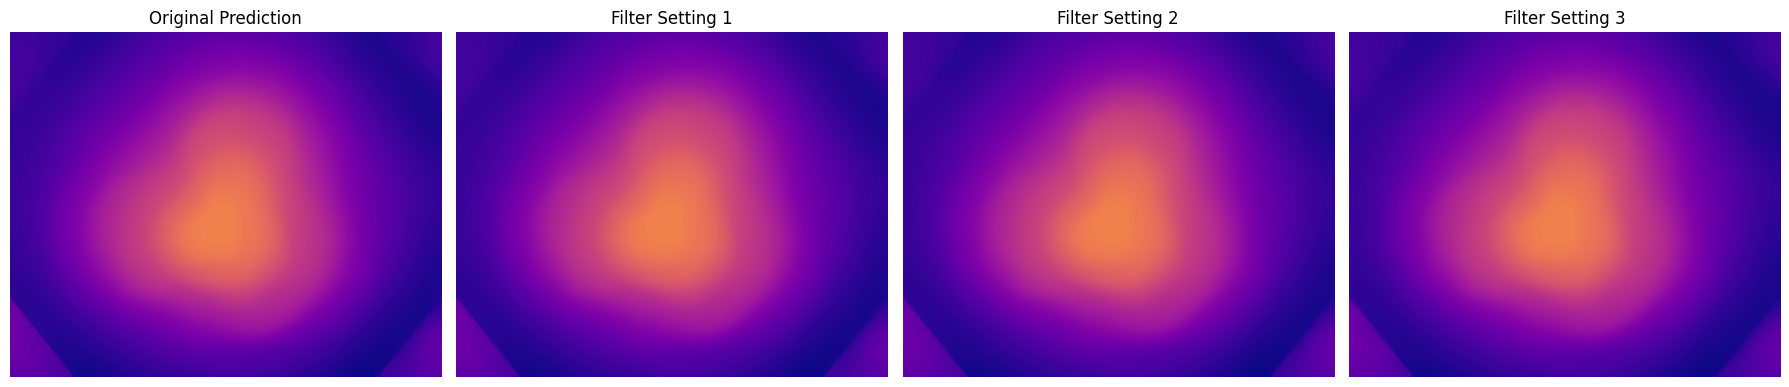

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Different filtering strengths
settings = [
    (9, 25, 5),
    (15, 50, 10),
    (25, 75, 15)
]

print("EDGE-AWARE FILTER COMPARISON")
print("-" * 50)
print(f"{'Setting':<20} {'MAE (mm)':<15}")

filtered_maps = []

for d, sigma_color, sigma_space in settings:

    refined = cv2.ximgproc.jointBilateralFilter(
        joint=guide,
        src=linear_depth,
        d=d,
        sigmaColor=sigma_color,
        sigmaSpace=sigma_space
    )

    mae = np.mean(
        np.abs(gt_mm[valid] - refined[valid])
    )

    filtered_maps.append(refined)

    print(
        f"d={d}, sc={sigma_color}, ss={sigma_space}: "
        f"{mae:.6f}"
    )

print(f"\nOriginal MAE: {original_mae:.6f}")

# Visualize
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].imshow(linear_depth, cmap="plasma", vmin=0, vmax=100)
axes[0].set_title("Original Prediction")

for i, refined in enumerate(filtered_maps):
    axes[i+1].imshow(
        refined, cmap="plasma", vmin=0, vmax=100
    )
    axes[i+1].set_title(f"Filter Setting {i+1}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

MEAN SIGNED DEPTH ERROR
------------------------
0–20 mm: 0.123 mm
20–40 mm: -4.550 mm
40–60 mm: -2.981 mm
60–100 mm: 19.417 mm


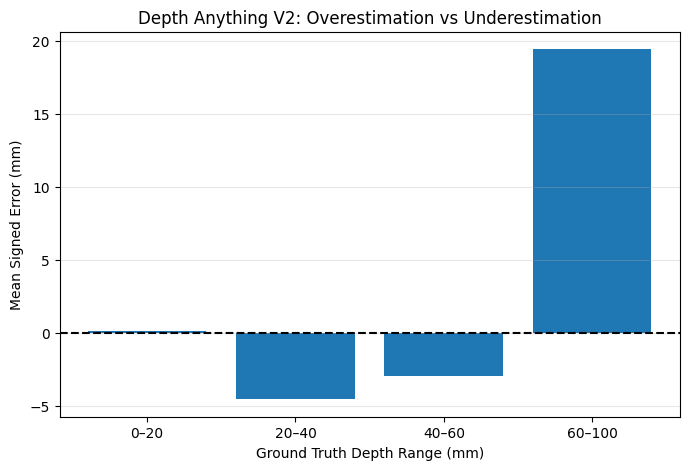

In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from common import CFG, sequence_dir, stream_results_dir

# Shared configuration paths
dev_folder = str(sequence_dir(CFG, "dev"))

output_folder = str(
    stream_results_dir(CFG, "DAv2") / "small" / "dev_predictions"
)

prediction_files = sorted([
    f for f in os.listdir(output_folder)
    if f.endswith("_pred.npy")
])

# Ground-truth depth intervals
depth_ranges = [(0, 20), (20, 40), (40, 60), (60, 100)]

error_sums = np.zeros(4, dtype=np.float64)
pixel_counts = np.zeros(4, dtype=np.int64)

for filename in prediction_files:

    # Load saved Small model prediction
    pred = np.load(
        os.path.join(output_folder, filename)
    )

    frame = filename.replace("_pred.npy", "")

    # Load ground-truth depth
    gt_raw = cv2.imread(
        os.path.join(dev_folder, f"{frame}_depth.tiff"),
        cv2.IMREAD_UNCHANGED
    )

    # Load RGB image
    rgb = cv2.imread(
        os.path.join(dev_folder, f"{frame}_color.png")
    )

    if gt_raw is None or rgb is None:
        raise FileNotFoundError(f"Missing image for {frame}")

    # Convert ground truth to millimeters
    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

    # Apply development-fitted linear calibration
    pred_mm = np.clip(
        -scale * pred + offset,
        1e-3,
        100.0
    )

    # Group evaluation protocol: Mask A
    valid = (
        (gt_raw > 0) &
        (gt_raw < 65535) &
        (rgb.max(axis=2) > 10)
    )

    # Positive = underestimation
    # Negative = overestimation
    signed_error = gt_mm - pred_mm

    for i, (low, high) in enumerate(depth_ranges):

        if high == 100:
            mask = (
                valid &
                (gt_mm >= low) &
                (gt_mm <= high)
            )
        else:
            mask = (
                valid &
                (gt_mm >= low) &
                (gt_mm < high)
            )

        error_sums[i] += np.sum(
            signed_error[mask],
            dtype=np.float64
        )

        pixel_counts[i] += np.count_nonzero(mask)

# Calculate mean signed error for each range
mean_signed_errors = np.divide(
    error_sums,
    pixel_counts,
    out=np.full(4, np.nan),
    where=pixel_counts > 0
)

labels = ["0–20", "20–40", "40–60", "60–100"]

print("MEAN SIGNED DEPTH ERROR — MASK A")
print("--------------------------------")

for label, error, count in zip(
    labels, mean_signed_errors, pixel_counts
):
    print(
        f"{label} mm: "
        f"Signed Error = {error:.4f} mm | "
        f"Pixels = {count}"
    )

# Plot results
plt.figure(figsize=(8, 5))

plt.bar(labels, mean_signed_errors)

plt.axhline(
    0,
    color="black",
    linestyle="--"
)

plt.xlabel("Ground Truth Depth Range (mm)")
plt.ylabel("Mean Signed Error (mm)")
plt.title("DAv2 Small — Depth Overestimation vs Underestimation (Mask A)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

ERROR BY PREDICTED DEPTH
---------------------------------------------
0–20 mm: Signed Error = 1.852 mm, Pixels = 42761235
20–40 mm: Signed Error = -5.170 mm, Pixels = 21284495
40–60 mm: Signed Error = -5.013 mm, Pixels = 13919401
60–80 mm: Signed Error = 20.718 mm, Pixels = 4747880
80–100 mm: Signed Error = nan mm, Pixels = 0


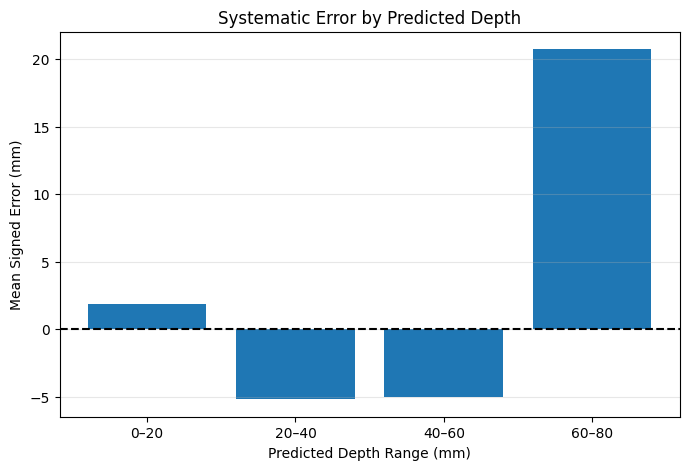

In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

from common import CFG, sequence_dir, stream_results_dir

# Shared configuration paths
dev_folder = str(sequence_dir(CFG, "dev"))

output_folder = str(
    stream_results_dir(CFG, "DAv2") / "small" / "dev_predictions"
)

prediction_files = sorted([
    f for f in os.listdir(output_folder)
    if f.endswith("_pred.npy")
])

# Predicted-depth intervals
bins = [0, 20, 40, 60, 80, 100]

error_sums = np.zeros(5, dtype=np.float64)
pixel_counts = np.zeros(5, dtype=np.int64)

for filename in prediction_files:

    frame = filename.replace("_pred.npy", "")

    # Load saved Small model prediction
    pred = np.load(
        os.path.join(output_folder, filename)
    )

    # Load ground-truth depth
    gt_raw = cv2.imread(
        os.path.join(dev_folder, f"{frame}_depth.tiff"),
        cv2.IMREAD_UNCHANGED
    )

    # Load corresponding RGB image
    rgb = cv2.imread(
        os.path.join(dev_folder, f"{frame}_color.png")
    )

    if gt_raw is None or rgb is None:
        raise FileNotFoundError(
            f"Missing RGB or depth image for frame {frame}"
        )

    # Convert ground truth to millimeters
    gt_mm = gt_raw.astype(np.float32) * (100.0 / 65535.0)

    # Apply development-fitted linear calibration
    pred_mm = np.clip(
        -scale * pred + offset,
        1e-3,
        100.0
    )

    # Group evaluation protocol: Mask A
    valid = (
        (gt_raw > 0) &
        (gt_raw < 65535) &
        (rgb.max(axis=2) > 10)
    )

    # Positive error = depth underestimation
    # Negative error = depth overestimation
    signed_error = gt_mm - pred_mm

    # Calculate errors for each predicted-depth interval
    for i in range(len(bins) - 1):

        low = bins[i]
        high = bins[i + 1]

        if high == 100:
            mask = (
                valid &
                (pred_mm >= low) &
                (pred_mm <= high)
            )
        else:
            mask = (
                valid &
                (pred_mm >= low) &
                (pred_mm < high)
            )

        error_sums[i] += np.sum(
            signed_error[mask],
            dtype=np.float64
        )

        pixel_counts[i] += np.count_nonzero(mask)

# Mean signed error in each interval
mean_errors = np.divide(
    error_sums,
    pixel_counts,
    out=np.full(5, np.nan),
    where=pixel_counts > 0
)

labels = ["0–20", "20–40", "40–60", "60–80", "80–100"]

print("ERROR BY PREDICTED DEPTH — MASK A")
print("-" * 55)

for label, error, count in zip(
    labels, mean_errors, pixel_counts
):
    print(
        f"{label} mm: "
        f"Signed Error = {error:.4f} mm | "
        f"Pixels = {count}"
    )

# Plot results
plt.figure(figsize=(8, 5))

plt.bar(labels, mean_errors)

plt.axhline(
    0,
    color="black",
    linestyle="--"
)

plt.xlabel("Predicted Depth Range (mm)")
plt.ylabel("Mean Signed Error (mm)")
plt.title("DAv2 Small — Systematic Error by Predicted Depth (Mask A)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
import os
import numpy as np

# Existing saved predictions from trans_t1_a
all_files = sorted([
    f for f in os.listdir(output_folder)
    if f.endswith("_pred.npy")
])

train_files = all_files[:45]
val_files = all_files[45:]

print("Training frames:", len(train_files))
print("Validation frames:", len(val_files))

print("\nTraining:")
print(train_files[0], "to", train_files[-1])

print("\nValidation:")
print(val_files[0], "to", val_files[-1])

Training frames: 45
Validation frames: 16

Training:
0000_pred.npy to 0044_pred.npy

Validation:
0045_pred.npy to 0060_pred.npy


In [69]:
from pathlib import Path
from common import CFG, sequence_dir, stream_results_dir

dev_folder = str(sequence_dir(CFG, "dev"))

output_folder = Path(
    stream_results_dir(CFG, "DAv2")
    / "small" / "dev_predictions"
)

# Use the same prediction source as the verified evaluation
if not list(output_folder.glob("*_pred.npy")):
    output_folder = Path(
        "/content/gdrive/MyDrive/"
        "BN5211_Depth_Estimation/DepthAnythingV2/dev_predictions"
    )

prediction_files = sorted(output_folder.glob("*_pred.npy"))

assert len(prediction_files) == 61

train_files = [p.name for p in prediction_files[:45]]
val_files = [p.name for p in prediction_files[45:]]

print("Training frames:", len(train_files))
print("Validation frames:", len(val_files))
print("Prediction folder:", output_folder)

Training frames: 45
Validation frames: 16
Prediction folder: /content/c3vd-main/results/DAv2/small/dev_predictions


In [70]:
import os
import cv2
import numpy as np

from common import CFG, sequence_dir, stream_results_dir

dev_folder = str(sequence_dir(CFG, "dev"))
output_folder = str(
    stream_results_dir(CFG, "DAv2") / "small" / "dev_predictions"
)

n = 0
sx = sy = sxx = sxy = 0.0

for filename in train_files:

    frame = filename.replace("_pred.npy", "")

    pred = np.load(os.path.join(output_folder, filename))

    gt_raw = cv2.imread(
        os.path.join(dev_folder, f"{frame}_depth.tiff"),
        cv2.IMREAD_UNCHANGED
    )

    rgb = cv2.imread(
        os.path.join(dev_folder, f"{frame}_color.png")
    )

    if gt_raw is None or rgb is None:
        raise FileNotFoundError(frame)

    gt_mm = gt_raw.astype(np.float32) * (100.0 / 65535.0)

    # Group protocol: Mask A
    valid = (
        (gt_raw > 0) &
        (gt_raw < 65535) &
        (rgb.max(axis=2) > 10)
    )

    x = -pred[valid].astype(np.float64)
    y = gt_mm[valid].astype(np.float64)

    n += x.size
    sx += x.sum()
    sy += y.sum()
    sxx += np.dot(x, x)
    sxy += np.dot(x, y)

denominator = sxx - sx * sx / n

train_scale = (sxy - sx * sy / n) / denominator
train_offset = (sy - train_scale * sx) / n

print("TRAINING-ONLY LINEAR CALIBRATION — MASK A")
print("Training frames:", len(train_files))
print("Valid training pixels:", n)
print("Scale:", train_scale)
print("Offset:", train_offset)

TRAINING-ONLY LINEAR CALIBRATION — MASK A
Training frames: 45
Valid training pixels: 59644667
Scale: 13.007499442648554
Offset: 62.606467056923826


In [38]:
from common import CFG, stream_results_dir
from pathlib import Path

output_folder = (
    stream_results_dir(CFG, "DAv2")
    / "small" / "dev_predictions"
)

prediction_files = sorted(output_folder.glob("*_pred.npy"))

assert len(prediction_files) == 61, (
    f"Expected 61 predictions, found {len(prediction_files)}"
)

train_files = [p.name for p in prediction_files[:45]]
val_files = [p.name for p in prediction_files[45:]]

print("Training frames:", len(train_files))
print("Validation frames:", len(val_files))
print("First training frame:", train_files[0])
print("Last training frame:", train_files[-1])
print("First validation frame:", val_files[0])

Training frames: 45
Validation frames: 16
First training frame: 0000_pred.npy
Last training frame: 0044_pred.npy
First validation frame: 0045_pred.npy


In [ ]:
import numpy as np

# Predicted-depth intervals in millimeters
bins = np.array([0, 20, 40, 60, 80, 100])

# Apply training-only linear calibration
train_pred_mm = np.clip(
    train_scale * X_train[:, 0] + train_offset,
    1e-3,
    100.0
)

# Calculate signed errors
train_errors = y_train - train_pred_mm

# Learn correction for each predicted-depth range
corrections = []
counts = []

for i in range(len(bins) - 1):

    low = bins[i]
    high = bins[i + 1]

    if high == 100:
        mask = (train_pred_mm >= low) & (train_pred_mm <= high)
    else:
        mask = (train_pred_mm >= low) & (train_pred_mm < high)

    count = np.count_nonzero(mask)

    if count > 0:
        correction = float(np.mean(train_errors[mask]))
    else:
        correction = 0.0

    corrections.append(correction)
    counts.append(count)

print("LEARNED DEPTH CORRECTIONS")
print("-" * 55)

for i in range(len(corrections)):
    print(
        f"{bins[i]}-{bins[i+1]} mm: "
        f"Correction = {corrections[i]:.3f} mm, "
        f"Pixels = {counts[i]}"
    )

print("\nBias correction model trained successfully!")

LEARNED DEPTH CORRECTIONS
-------------------------------------------------------
0-20 mm: Correction = 1.857 mm, Pixels = 30700131
20-40 mm: Correction = -5.211 mm, Pixels = 16355948
40-60 mm: Correction = -4.206 mm, Pixels = 10902135
60-80 mm: Correction = 23.373 mm, Pixels = 3059581
80-100 mm: Correction = 0.000 mm, Pixels = 0

Bias correction model trained successfully!


Original MAE: 5.7090025
Corrected MAE: 4.7585278


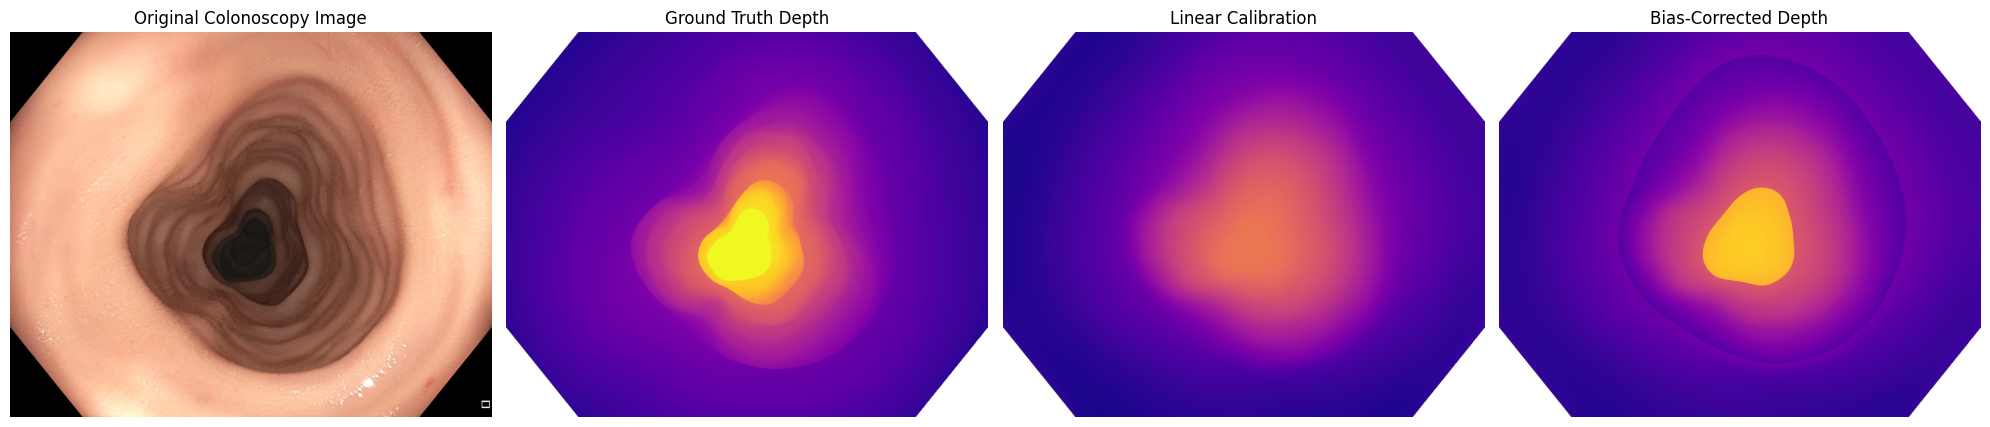

In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

# First validation frame
frame = "0045"

from common import CFG, sequence_dir, stream_results_dir

folder = str(sequence_dir(CFG, "dev"))
pred_folder = str(
    stream_results_dir(CFG, "DAv2") / "small" / "dev_predictions"
)
rgb = cv2.imread(f"{folder}/{frame}_color.png")
rgb = cv2.cvtColor(rgb, cv2.COLOR_BGR2RGB)

gt_raw = cv2.imread(
    f"{folder}/{frame}_depth.tiff",
    cv2.IMREAD_UNCHANGED
)

gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0
valid = (
    (gt_raw > 0) &
    (gt_raw < 65535) &
    (rgb.max(axis=2) > 10)
)
pred = np.load(f"{pred_folder}/{frame}_pred.npy")

# Original linear prediction
linear_depth = np.clip(
    -train_scale * pred + train_offset,
    1e-3, 100.0
)

# Apply bias correction
corrected_depth = linear_depth.copy()

for i in range(len(bins) - 1):
    low, high = bins[i], bins[i + 1]

    if high == 100:
        mask = (linear_depth >= low) & (linear_depth <= high)
    else:
        mask = (linear_depth >= low) & (linear_depth < high)

    corrected_depth[mask] += corrections[i]

corrected_depth = np.clip(corrected_depth, 1e-3, 100.0)

# Calculate absolute errors
linear_error = np.abs(gt_mm - linear_depth)
corrected_error = np.abs(gt_mm - corrected_depth)

print("Original MAE:", np.mean(linear_error[valid]))
print("Corrected MAE:", np.mean(corrected_error[valid]))

# Display results
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

images = [
    rgb,
    np.where(valid, gt_mm, np.nan),
    np.where(valid, linear_depth, np.nan),
    np.where(valid, corrected_depth, np.nan)
]

titles = [
    "Original Colonoscopy Image",
    "Ground Truth Depth",
    "Linear Calibration",
    "Bias-Corrected Depth"
]

for i, ax in enumerate(axes):
    if i == 0:
        ax.imshow(images[i])
    else:
        ax.imshow(images[i], cmap="plasma", vmin=0, vmax=100)

    ax.set_title(titles[i])
    ax.axis("off")

plt.tight_layout()
plt.show()

Original MAE: 5.7090025
Piecewise corrected MAE: 4.7585278
Smooth corrected MAE: 4.49686470979312


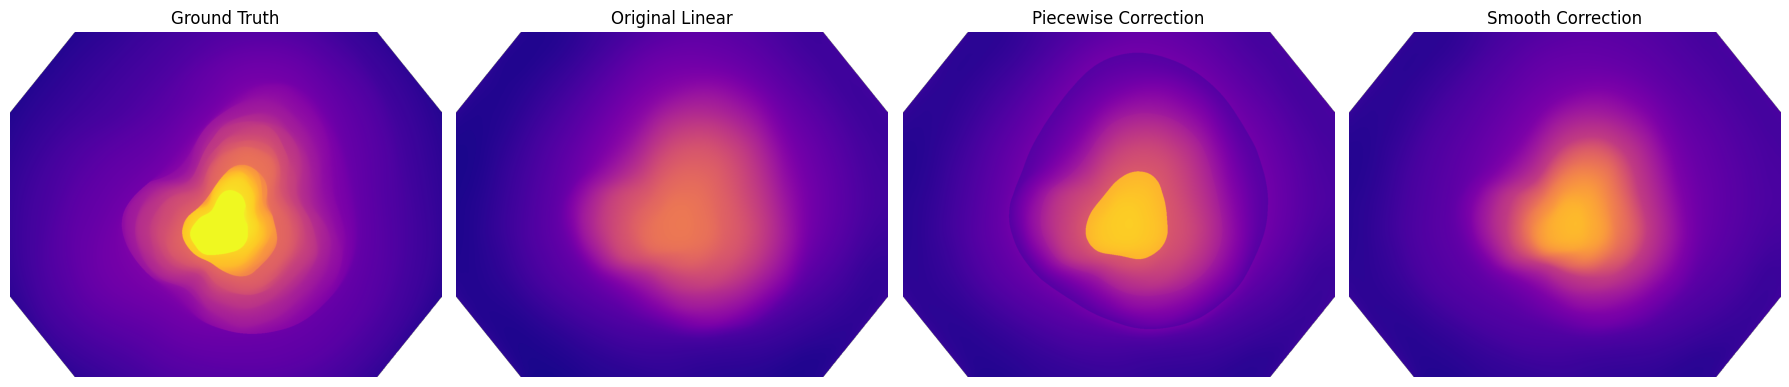

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Midpoints of the trained depth intervals
bin_centers = np.array([10, 30, 50, 70], dtype=np.float32)

# Corrections learned from 45 training frames
bin_corrections = np.array(corrections[:4], dtype=np.float32)

# Interpolate corrections smoothly
smooth_correction = np.interp(
    linear_depth,
    bin_centers,
    bin_corrections
)

# Apply correction
smooth_depth = np.clip(
    linear_depth + smooth_correction,
    1e-3,
    100.0
)

# Calculate MAE
smooth_mae = np.mean(
    np.abs(gt_mm[valid] - smooth_depth[valid])
)

print("Original MAE:", np.mean(
    np.abs(gt_mm[valid] - linear_depth[valid])
))

print("Piecewise corrected MAE:", np.mean(
    np.abs(gt_mm[valid] - corrected_depth[valid])
))

print("Smooth corrected MAE:", smooth_mae)

# Visualize
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

maps = [
    gt_mm,
    linear_depth,
    corrected_depth,
    smooth_depth
]

titles = [
    "Ground Truth",
    "Original Linear",
    "Piecewise Correction",
    "Smooth Correction"
]

for ax, depth_map, title in zip(axes, maps, titles):
    ax.imshow(
        np.where(valid, depth_map, np.nan),
        cmap="plasma",
        vmin=0,
        vmax=100
    )
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import os
import cv2
import numpy as np

from common import CFG, sequence_dir, stream_results_dir

# Shared configuration paths
dev_folder = str(sequence_dir(CFG, "dev"))

output_folder = str(
    stream_results_dir(CFG, "DAv2") / "small" / "dev_predictions"
)

prediction_files = sorted([
    f for f in os.listdir(output_folder)
    if f.endswith("_pred.npy")
])

assert len(prediction_files) == 61, (
    f"Expected 61 development predictions, found {len(prediction_files)}"
)

# Fixed depth intervals
bins = np.array([0, 20, 40, 60, 80, 100])

# Retain original bin-center definition for now
bin_centers = np.array([10, 30, 50, 70])

error_sums = np.zeros(5, dtype=np.float64)
pixel_counts = np.zeros(5, dtype=np.int64)

for filename in prediction_files:

    frame = filename.replace("_pred.npy", "")

    # Load saved DAv2 Small prediction
    pred = np.load(
        os.path.join(output_folder, filename)
    )

    # Load ground-truth depth
    gt_raw = cv2.imread(
        os.path.join(dev_folder, f"{frame}_depth.tiff"),
        cv2.IMREAD_UNCHANGED
    )

    # Load RGB image
    rgb = cv2.imread(
        os.path.join(dev_folder, f"{frame}_color.png")
    )

    if gt_raw is None or rgb is None:
        raise FileNotFoundError(
            f"Missing RGB or depth image for frame {frame}"
        )

    # Convert ground truth to millimeters
    gt_mm = gt_raw.astype(np.float32) * (100.0 / 65535.0)

    # Apply development-fitted linear calibration
    pred_mm = np.clip(
        -scale * pred + offset,
        1e-3,
        100.0
    )

    # Group evaluation protocol: Mask A
    valid = (
        (gt_raw > 0) &
        (gt_raw < 65535) &
        (rgb.max(axis=2) > 10)
    )

    # Positive = underestimation
    # Negative = overestimation
    signed_error = gt_mm - pred_mm

    # Calculate correction for each predicted-depth interval
    for i in range(len(bins) - 1):

        low = bins[i]
        high = bins[i + 1]

        if high == 100:
            mask = (
                valid &
                (pred_mm >= low) &
                (pred_mm <= high)
            )
        else:
            mask = (
                valid &
                (pred_mm >= low) &
                (pred_mm < high)
            )

        error_sums[i] += np.sum(
            signed_error[mask],
            dtype=np.float64
        )

        pixel_counts[i] += np.count_nonzero(mask)

# Calculate mean correction in each interval
final_corrections = np.divide(
    error_sums,
    pixel_counts,
    out=np.zeros(5, dtype=np.float64),
    where=pixel_counts > 0
)

print("SMOOTH CORRECTION PARAMETERS — MASK A")
print("-" * 60)

for i in range(len(final_corrections)):
    print(
        f"{bins[i]}–{bins[i+1]} mm: "
        f"Correction = {final_corrections[i]:.4f} mm | "
        f"Pixels = {pixel_counts[i]}"
    )

print("\nCorrection parameters calculated successfully!")

FINAL SMOOTH CORRECTION PARAMETERS
-------------------------------------------------------
0-20 mm: Correction = 1.852 mm, Pixels = 42761235
20-40 mm: Correction = -5.170 mm, Pixels = 21284495
40-60 mm: Correction = -5.013 mm, Pixels = 13919401
60-80 mm: Correction = 20.718 mm, Pixels = 4747880
80-100 mm: Correction = 0.000 mm, Pixels = 0

Final correction model ready!


In [45]:
import json
from pathlib import Path

params_path = Path(
    "/content/gdrive/MyDrive/"
    "BN5211_Depth_Estimation/DepthAnythingV2/"
    "DAv2_GroupProtocol_A/calibration_parameters_maskA.json"
)

if not params_path.exists():
    raise FileNotFoundError(params_path)

with open(params_path, "r") as f:
    params = json.load(f)

print(json.dumps(params, indent=2))

{
  "Small": {
    "scale": 13.321026124555381,
    "offset": 64.22639769237846,
    "dev_valid_pixels": 80948601,
    "raw_units": "relative"
  },
  "Small_smooth": {
    "bin_centers_mm": [
      10.0,
      30.0,
      50.0,
      70.0
    ],
    "corrections_mm": [
      1.1854982670035257,
      -4.087490818371066,
      1.6420928046873542,
      23.402725890497383,
      0.0
    ],
    "bin_counts": [
      43403338,
      22633111,
      14177279,
      734873,
      0
    ],
    "note": "Only first 4 bins interpolated; 80-100 had no training pixels if count zero"
  },
  "Base": {
    "scale": 6.714576406016308,
    "offset": 66.92887628456685,
    "dev_valid_pixels": 80948601,
    "raw_units": "relative"
  },
  "Large": {
    "scale": 0.20152337107850277,
    "offset": 70.30650360281635,
    "dev_valid_pixels": 80948601,
    "raw_units": "relative"
  },
  "Indoor": {
    "scale": 0.03455463424211869,
    "offset": -16.298106971353,
    "dev_valid_pixels": 80948601,
    "raw_uni

In [46]:
import json
import numpy as np
from pathlib import Path

params_path = Path(
    "/content/gdrive/MyDrive/"
    "BN5211_Depth_Estimation/DepthAnythingV2/"
    "DAv2_GroupProtocol_A/calibration_parameters_maskA.json"
)

with open(params_path, "r") as f:
    params = json.load(f)

# Final 61-frame development calibration
scale = params["Small"]["scale"]
offset = params["Small"]["offset"]

# Verified smooth correction
bin_centers = np.array(
    params["Small_smooth"]["bin_centers_mm"],
    dtype=np.float64
)

final_corrections = np.array(
    params["Small_smooth"]["corrections_mm"],
    dtype=np.float64
)

# Only four corrections are used for interpolation
corrections = final_corrections[:4]

print("Scale:", scale)
print("Offset:", offset)
print("Bin centers:", bin_centers)
print("Interpolation corrections:", corrections)

Scale: 13.321026124555381
Offset: 64.22639769237846
Bin centers: [10. 30. 50. 70.]
Interpolation corrections: [ 1.18549827 -4.08749082  1.6420928  23.40272589]


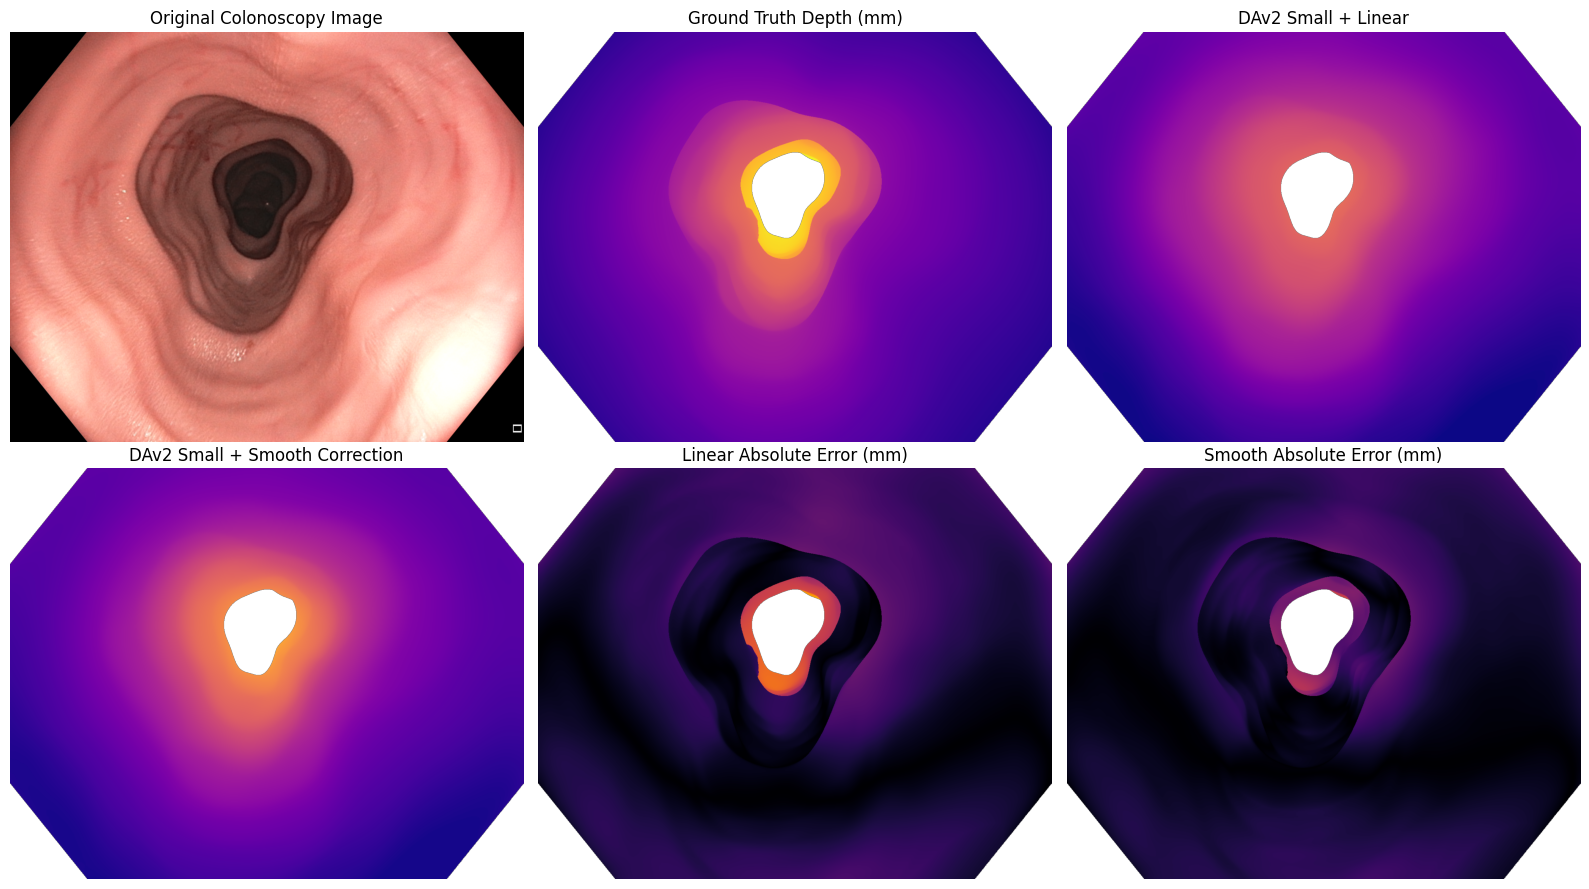

FRAME: 0001
Linear MAE: 6.1191 mm
Smooth MAE: 4.8955 mm
MAE improvement: 1.2237 mm
Figure saved to: /content/c3vd-main/results/DAv2/small_smooth_final_comparison.png


In [52]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from common import CFG, sequence_dir, stream_results_dir, load_frame

# Select test frame
frame = "0001"

# Shared paths
test_folder = sequence_dir(CFG, "test")

test_output = (
    stream_results_dir(CFG, "DAv2")
    / "small" / "test_predictions"
)

save_folder = stream_results_dir(CFG, "DAv2")

# Load RGB image and ground truth using shared loader
color_path = test_folder / f"{frame}_color.png"

rgb, gt_mm, valid = load_frame(color_path)

# Load saved DAv2 Small prediction
pred_path = test_output / f"{frame}_pred.npy"

if not pred_path.exists():
    raise FileNotFoundError(pred_path)

pred = np.load(pred_path)

# Use verified final Mask A calibration parameters
scale = params["Small"]["scale"]
offset = params["Small"]["offset"]

centers = np.array(
    params["Small_smooth"]["bin_centers_mm"],
    dtype=np.float64
)

corrections = np.array(
    params["Small_smooth"]["corrections_mm"][:4],
    dtype=np.float64
)

# Original linear calibration
linear = np.clip(
    -scale * pred + offset,
    1e-3,
    100.0
)

# Smooth depth-dependent correction
smooth = np.clip(
    linear + np.interp(
        linear,
        centers,
        corrections
    ),
    1e-3,
    100.0
)

# Verify prediction dimensions
assert linear.shape == gt_mm.shape
assert smooth.shape == gt_mm.shape

# Mask invalid pixels
gt_display = np.where(valid, gt_mm, np.nan)
linear_display = np.where(valid, linear, np.nan)
smooth_display = np.where(valid, smooth, np.nan)

# Absolute error maps
linear_error = np.where(
    valid,
    np.abs(gt_mm - linear),
    np.nan
)

smooth_error = np.where(
    valid,
    np.abs(gt_mm - smooth),
    np.nan
)

# Create comparison figure
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

axes[0, 0].imshow(rgb)
axes[0, 0].set_title("Original Colonoscopy Image")

axes[0, 1].imshow(
    gt_display,
    cmap="plasma",
    vmin=0,
    vmax=100
)
axes[0, 1].set_title("Ground Truth Depth (mm)")

axes[0, 2].imshow(
    linear_display,
    cmap="plasma",
    vmin=0,
    vmax=100
)
axes[0, 2].set_title("DAv2 Small + Linear")

axes[1, 0].imshow(
    smooth_display,
    cmap="plasma",
    vmin=0,
    vmax=100
)
axes[1, 0].set_title("DAv2 Small + Smooth Correction")

axes[1, 1].imshow(
    linear_error,
    cmap="inferno",
    vmin=0,
    vmax=50
)
axes[1, 1].set_title("Linear Absolute Error (mm)")

axes[1, 2].imshow(
    smooth_error,
    cmap="inferno",
    vmin=0,
    vmax=50
)
axes[1, 2].set_title("Smooth Absolute Error (mm)")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()

# Save figure in configured results folder
save_path = save_folder / "small_smooth_final_comparison.png"

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Calculate MAE for this frame
linear_mae = np.mean(
    np.abs(gt_mm[valid] - linear[valid])
)

smooth_mae = np.mean(
    np.abs(gt_mm[valid] - smooth[valid])
)

print("FRAME:", frame)
print("Linear MAE:", round(linear_mae, 4), "mm")
print("Smooth MAE:", round(smooth_mae, 4), "mm")
print("MAE improvement:", round(linear_mae - smooth_mae, 4), "mm")
print("Figure saved to:", save_path)

In [55]:
import numpy as np

from common import CFG, sequence_dir, stream_results_dir, load_frame

# Shared paths
test_folder = sequence_dir(CFG, "test")

test_output = (
    stream_results_dir(CFG, "DAv2")
    / "small" / "test_predictions"
)

# Verified final Mask A calibration
scale = params["Small"]["scale"]
offset = params["Small"]["offset"]

centers = np.array(
    params["Small_smooth"]["bin_centers_mm"],
    dtype=np.float64
)

corrections = np.array(
    params["Small_smooth"]["corrections_mm"][:4],
    dtype=np.float64
)

frame_errors = []

# Evaluate all 103 test frames
prediction_files = sorted(test_output.glob("*_pred.npy"))

assert len(prediction_files) == 103, (
    f"Expected 103 test predictions, found {len(prediction_files)}"
)

for pred_path in prediction_files:

    frame = pred_path.name.replace("_pred.npy", "")

    # Load RGB, ground truth and Mask A
    color_path = test_folder / f"{frame}_color.png"

    rgb, gt_mm, valid = load_frame(color_path)

    # Load saved prediction
    pred = np.load(pred_path)

    # Apply linear calibration
    linear = np.clip(
        -scale * pred + offset,
        1e-3,
        100.0
    )

    # Apply final smooth correction
    improved = np.clip(
        linear + np.interp(
            linear,
            centers,
            corrections
        ),
        1e-3,
        100.0
    )

    # Verify dimensions and valid pixels
    assert improved.shape == gt_mm.shape

    if not np.any(valid):
        raise ValueError(f"No valid pixels in frame {frame}")

    # Calculate frame-level RMSE using Mask A
    gt = gt_mm[valid].astype(np.float64)
    prediction = improved[valid].astype(np.float64)

    rmse = np.sqrt(
        np.mean((gt - prediction) ** 2)
    )

    mae = np.mean(np.abs(gt - prediction))

    frame_errors.append({
        "Frame": frame,
        "RMSE_mm": float(rmse),
        "MAE_mm": float(mae)
    })

# Sort frames by RMSE, highest first
frame_errors.sort(
    key=lambda x: x["RMSE_mm"],
    reverse=True
)

print("TOP 3 FAILURE CASES — MASK A")
print("-" * 45)

for item in frame_errors[:3]:
    print(
        f"Frame {item['Frame']}: "
        f"RMSE={item['RMSE_mm']:.4f} mm | "
        f"MAE={item['MAE_mm']:.4f} mm"
    )

print("\nTOP 3 BEST CASES — MASK A")
print("-" * 45)

for item in frame_errors[-3:][::-1]:
    print(
        f"Frame {item['Frame']}: "
        f"RMSE={item['RMSE_mm']:.4f} mm | "
        f"MAE={item['MAE_mm']:.4f} mm"
    )

print("\nTotal test frames evaluated:", len(frame_errors))

TOP 3 FAILURE CASES — MASK A
---------------------------------------------
Frame 0072: RMSE=6.8235 mm | MAE=5.9367 mm
Frame 0078: RMSE=6.7773 mm | MAE=5.7750 mm
Frame 0076: RMSE=6.7290 mm | MAE=5.8376 mm

TOP 3 BEST CASES — MASK A
---------------------------------------------
Frame 0061: RMSE=4.4147 mm | MAE=3.1918 mm
Frame 0060: RMSE=4.4558 mm | MAE=3.3004 mm
Frame 0066: RMSE=4.4957 mm | MAE=3.4294 mm

Total test frames evaluated: 103


Frame 0072: MAE=5.9367 mm | RMSE=6.8235 mm
Frame 0076: MAE=5.8376 mm | RMSE=6.7290 mm
Frame 0078: MAE=5.7750 mm | RMSE=6.7773 mm


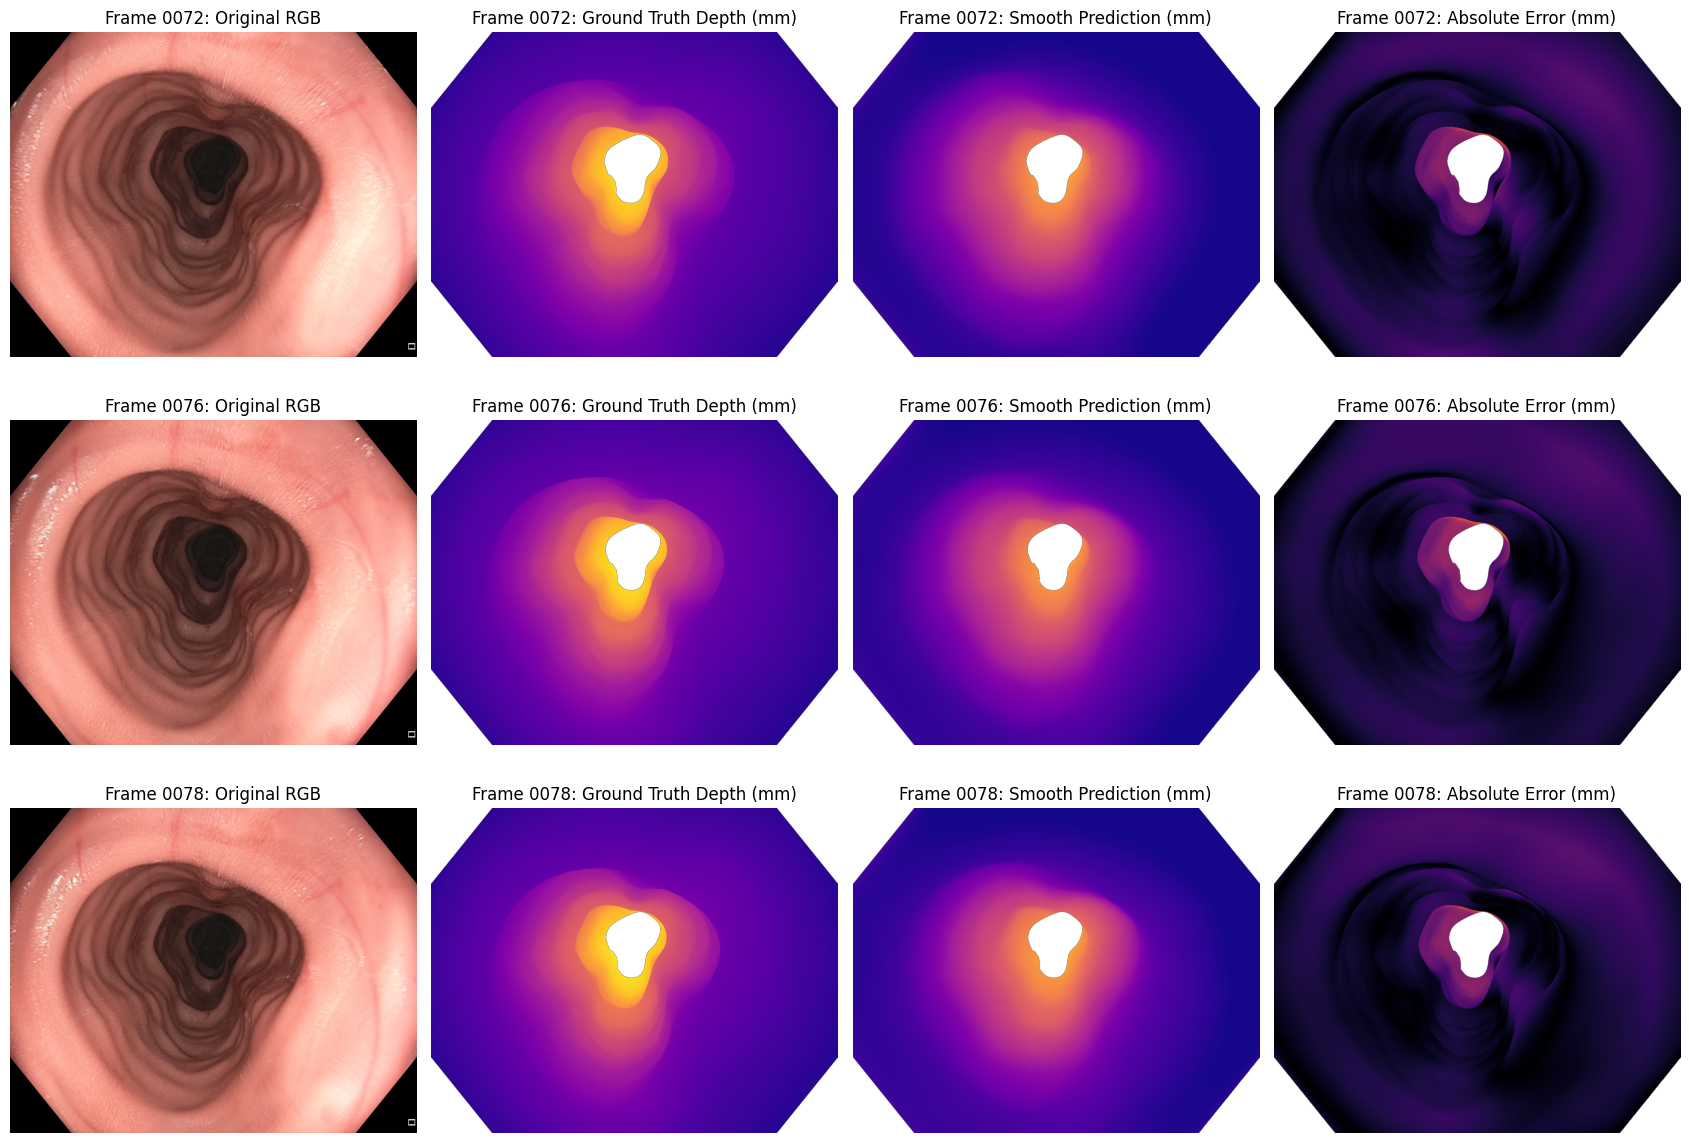

Failure-case figure saved to: /content/c3vd-main/results/DAv2/failure_cases.png


In [54]:
import numpy as np
import matplotlib.pyplot as plt

from common import CFG, sequence_dir, stream_results_dir, load_frame

# Selected test frames for failure-case analysis
failure_frames = ["0072", "0076", "0078"]

# Shared configuration paths
test_folder = sequence_dir(CFG, "test")

test_output = (
    stream_results_dir(CFG, "DAv2")
    / "small" / "test_predictions"
)

save_folder = stream_results_dir(CFG, "DAv2")

# Verified Mask A calibration parameters
scale = params["Small"]["scale"]
offset = params["Small"]["offset"]

centers = np.array(
    params["Small_smooth"]["bin_centers_mm"],
    dtype=np.float64
)

corrections = np.array(
    params["Small_smooth"]["corrections_mm"][:4],
    dtype=np.float64
)

# Create visualization
fig, axes = plt.subplots(3, 4, figsize=(17, 12))

for row, frame in enumerate(failure_frames):

    # Load RGB, ground truth and Mask A
    color_path = test_folder / f"{frame}_color.png"

    rgb, gt_mm, valid = load_frame(color_path)

    # Load saved DAv2 Small prediction
    pred_path = test_output / f"{frame}_pred.npy"

    if not pred_path.exists():
        raise FileNotFoundError(pred_path)

    pred = np.load(pred_path)

    # Original linear calibration
    linear = np.clip(
        -scale * pred + offset,
        1e-3,
        100.0
    )

    # Final smooth depth-dependent correction
    smooth = np.clip(
        linear + np.interp(
            linear,
            centers,
            corrections
        ),
        1e-3,
        100.0
    )

    # Verify dimensions
    assert smooth.shape == gt_mm.shape

    # Absolute error map
    error = np.abs(gt_mm - smooth)

    # Mask invalid pixels
    images = [
        rgb,
        np.where(valid, gt_mm, np.nan),
        np.where(valid, smooth, np.nan),
        np.where(valid, error, np.nan)
    ]

    titles = [
        "Original RGB",
        "Ground Truth Depth (mm)",
        "Smooth Prediction (mm)",
        "Absolute Error (mm)"
    ]

    # Display four panels for each frame
    for col in range(4):

        ax = axes[row, col]

        if col == 0:
            ax.imshow(images[col])
        else:
            ax.imshow(
                images[col],
                cmap="inferno" if col == 3 else "plasma",
                vmin=0,
                vmax=50 if col == 3 else 100
            )

        ax.set_title(f"Frame {frame}: {titles[col]}")
        ax.axis("off")

    # Calculate frame-level errors
    mae = np.mean(error[valid])

    rmse = np.sqrt(
        np.mean((gt_mm[valid] - smooth[valid]) ** 2)
    )

    print(
        f"Frame {frame}: "
        f"MAE={mae:.4f} mm | "
        f"RMSE={rmse:.4f} mm"
    )

plt.tight_layout()

# Save figure
save_path = save_folder / "failure_cases.png"

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Failure-case figure saved to:", save_path)

In [23]:
import torch

print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

GPU available: True
GPU: Tesla T4


In [ ]:
import os
import torch

print("Current directory:", os.getcwd())
print("Model code available:",
      os.path.exists("depth_anything_v2/dpt.py"))

print("GPU:", torch.cuda.get_device_name(0))

Current directory: /content/Depth-Anything-V2
Model code available: True
GPU: Tesla T4


In [ ]:
%cd /content/Depth-Anything-V2

from pathlib import Path

checkpoint = Path(
    "checkpoints/depth_anything_v2_vitl.pth"
)

checkpoint.parent.mkdir(parents=True, exist_ok=True)

if checkpoint.exists() and checkpoint.stat().st_size > 0:
    print("Large model checkpoint already exists.")
else:
    !wget -q --show-progress \
    https://huggingface.co/depth-anything/Depth-Anything-V2-Large/resolve/main/depth_anything_v2_vitl.pth \
    -O checkpoints/depth_anything_v2_vitl.pth

print("Checkpoint ready:", checkpoint.exists())

/content/Depth-Anything-V2
checkpoints/depth_a 100%[===================>]   1.25G  62.7MB/s    in 21s     


In [ ]:
import os

model_path = "checkpoints/depth_anything_v2_vitl.pth"

print("Weights downloaded:", os.path.exists(model_path))
print("File size (GB):", round(os.path.getsize(model_path) / 1e9, 2))

Weights downloaded: True
File size (GB): 1.34


In [ ]:
import torch
from depth_anything_v2.dpt import DepthAnythingV2

# Configure Depth Anything V2 Large
model_large = DepthAnythingV2(
    encoder='vitl',
    features=256,
    out_channels=[256, 512, 1024, 1024]
)

# Load pretrained weights
model_large.load_state_dict(
    torch.load(
        'checkpoints/depth_anything_v2_vitl.pth',
        map_location='cpu',
        weights_only=True
    )
)

# Move model to GPU
device = 'cuda' if torch.cuda.is_available() else 'cpu'

model_large = model_large.to(device).eval()

print("Model loaded successfully!")
print("Model: Depth Anything V2 Large")
print("Running on:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

Model loaded successfully!
Model: Depth Anything V2 Large
Running on: cuda
GPU: Tesla T4


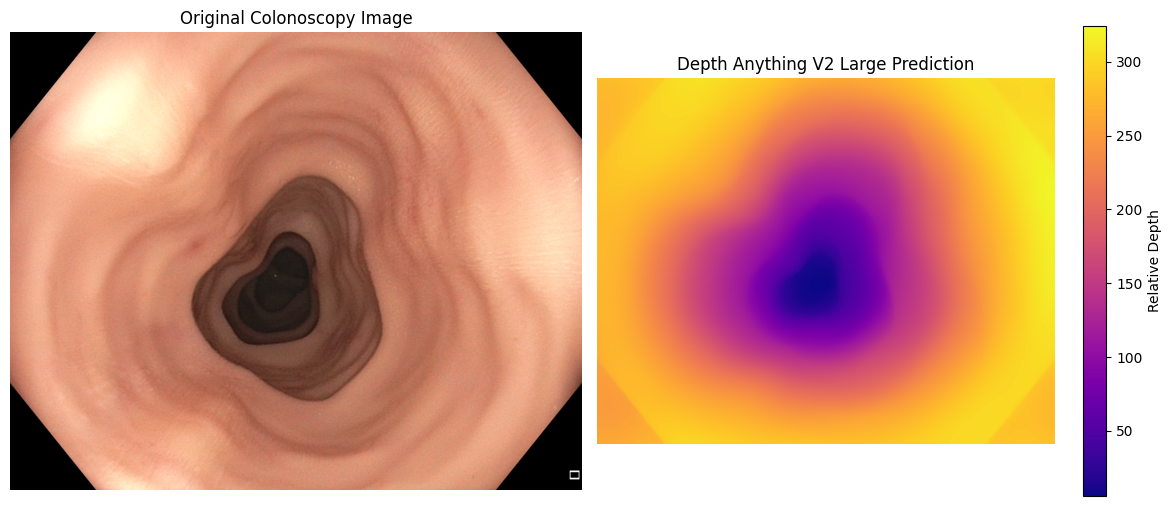

Prediction shape: (1080, 1350)
Minimum prediction: 5.9551625
Maximum prediction: 324.145


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch

# Load first C3VD development image
from common import CFG, sequence_dir

image_path = str(sequence_dir(CFG, "dev") / "0001_color.png")
image = cv2.imread(image_path)

if image is None:
    raise FileNotFoundError(image_path)

# Run Depth Anything V2 Large
with torch.inference_mode():
    predicted_large = model_large.infer_image(
        image,
        input_size=518
    )

# Display original image and prediction
rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(rgb)
plt.title("Original Colonoscopy Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(predicted_large, cmap="plasma")
plt.title("Depth Anything V2 Large Prediction")
plt.colorbar(label="Relative Depth")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Prediction shape:", predicted_large.shape)
print("Minimum prediction:", predicted_large.min())
print("Maximum prediction:", predicted_large.max())

In [ ]:
import os
import cv2
import numpy as np
import torch

from common import CFG, sequence_dir, stream_results_dir

dev_folder = str(sequence_dir(CFG, "dev"))
large_output = str(
    stream_results_dir(CFG, "DAv2") / "large" / "dev_predictions"
)

os.makedirs(large_output, exist_ok=True)

image_files = sorted([
    f for f in os.listdir(dev_folder)
    if f.endswith("_color.png")
])

print("Total development images:", len(image_files))

model_large.eval()

for i, filename in enumerate(image_files):

    image = cv2.imread(
        os.path.join(dev_folder, filename)
    )

    if image is None:
        raise RuntimeError(f"Cannot load {filename}")

    with torch.inference_mode():
        prediction = model_large.infer_image(
            image,
            input_size=518
        )

    output_name = filename.replace(
        "_color.png", "_pred.npy"
    )

    np.save(
        os.path.join(large_output, output_name),
        prediction.astype(np.float32)
    )

    if (i + 1) % 10 == 0 or i + 1 == len(image_files):
        print(f"Processed {i + 1}/{len(image_files)}")

print("All Large model development predictions saved!")

Total development images: 61
Processed 10/61
Processed 20/61
Processed 30/61
Processed 40/61
Processed 50/61
Processed 60/61
Processed 61/61
All Large model development predictions saved!


In [ ]:
import os
import cv2
import numpy as np
import torch

from common import CFG, sequence_dir, stream_results_dir

test_folder = str(sequence_dir(CFG, "test"))
large_test_output = str(
    stream_results_dir(CFG, "DAv2") / "large" / "test_predictions"
)
os.makedirs(large_test_output, exist_ok=True)

test_files = sorted([
    f for f in os.listdir(test_folder)
    if f.endswith("_color.png")
])

print("Total test images:", len(test_files))

model_large.eval()

for i, filename in enumerate(test_files):

    image = cv2.imread(
        os.path.join(test_folder, filename)
    )

    if image is None:
        raise RuntimeError(f"Cannot load {filename}")

    with torch.inference_mode():
        prediction = model_large.infer_image(
            image,
            input_size=518
        )

    output_name = filename.replace(
        "_color.png", "_pred.npy"
    )

    np.save(
        os.path.join(large_test_output, output_name),
        prediction.astype(np.float32)
    )

    if (i + 1) % 10 == 0 or i + 1 == len(test_files):
        print(f"Processed {i + 1}/{len(test_files)}")

print("All Large model test predictions saved!")

Total test images: 103
Processed 10/103
Processed 20/103
Processed 30/103
Processed 40/103
Processed 50/103
Processed 60/103
Processed 70/103
Processed 80/103
Processed 90/103
Processed 100/103
Processed 103/103
All Large model test predictions saved!


In [ ]:
%cd /content/Depth-Anything-V2

from pathlib import Path

checkpoint = Path(
    "checkpoints_metric/depth_anything_v2_metric_hypersim_vitl.pth"
)

checkpoint.parent.mkdir(parents=True, exist_ok=True)

if checkpoint.exists() and checkpoint.stat().st_size > 0:
    print("Large Indoor checkpoint already exists.")
else:
    !wget -q --show-progress \
    https://huggingface.co/depth-anything/Depth-Anything-V2-Metric-Indoor-Large/resolve/main/depth_anything_v2_metric_hypersim_vitl.pth \
    -O checkpoints_metric/depth_anything_v2_metric_hypersim_vitl.pth

print("Checkpoint ready:", checkpoint.exists())

/content/Depth-Anything-V2


In [ ]:
%cd /content/Depth-Anything-V2

!pip install -q huggingface_hub

from huggingface_hub import hf_hub_download
import os

indoor_path = hf_hub_download(
    repo_id="depth-anything/Depth-Anything-V2-Metric-Hypersim-Large",
    filename="depth_anything_v2_metric_hypersim_vitl.pth",
    local_dir="/content/Depth-Anything-V2/checkpoints_metric"
)

print("Downloaded:", os.path.exists(indoor_path))
print("File size (GB):", round(os.path.getsize(indoor_path) / 1e9, 2))

/content/Depth-Anything-V2


depth_anything_v2_metric_hypersim_vitl.p(…): reconstructing file:   0%|          |  0.00B / 1.34GB            

depth_anything_v2_metric_hypersim_vitl.p(…): downloading bytes:           |  0.00B            

Downloaded: True
File size (GB): 1.34


In [ ]:
import sys
import torch
from pathlib import Path

# Metric-depth implementation
metric_path = "/content/Depth-Anything-V2/metric_depth"

# Remove conflicting standard model modules
for name in list(sys.modules):
    if name == "depth_anything_v2" or name.startswith("depth_anything_v2."):
        del sys.modules[name]

if metric_path in sys.path:
    sys.path.remove(metric_path)

sys.path.insert(0, metric_path)

# Import metric-depth architecture
from depth_anything_v2.dpt import DepthAnythingV2 as MetricDepthAnythingV2

# Indoor checkpoint
indoor_path = Path(
    "/content/Depth-Anything-V2/checkpoints_metric/"
    "depth_anything_v2_metric_hypersim_vitl.pth"
)

if not indoor_path.exists():
    raise FileNotFoundError(indoor_path)

# Initialize Large Indoor model
model_indoor = MetricDepthAnythingV2(
    encoder="vitl",
    features=256,
    out_channels=[256, 512, 1024, 1024],
    max_depth=20
)

# Load pretrained weights
model_indoor.load_state_dict(
    torch.load(
        indoor_path,
        map_location="cpu",
        weights_only=True
    )
)

device = "cuda" if torch.cuda.is_available() else "cpu"

model_indoor = model_indoor.to(device).eval()

print("Large Indoor model loaded successfully!")
print("Running on:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Large Indoor model loaded successfully!
Running on: cuda:0


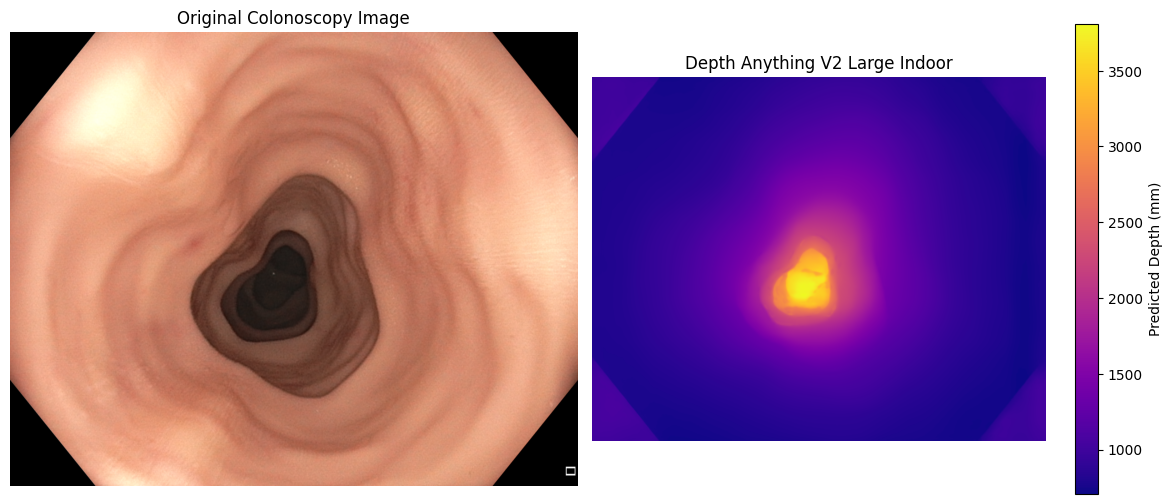

Prediction shape: (1080, 1350)
Minimum depth (mm): 706.9086
Maximum depth (mm): 3808.3015


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch

# Load first C3VD development image
from common import CFG, sequence_dir

image_path = str(sequence_dir(CFG, "dev") / "0001_color.png")
image = cv2.imread(image_path)

if image is None:
    raise FileNotFoundError(image_path)

# Generate Indoor model prediction
with torch.inference_mode():
    predicted_indoor = model_indoor.infer_image(
        image,
        input_size=518
    )

# Convert meters to millimeters
predicted_indoor_mm = predicted_indoor * 1000.0

# Display results
rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(rgb)
plt.title("Original Colonoscopy Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(predicted_indoor_mm, cmap="plasma")
plt.title("Depth Anything V2 Large Indoor")
plt.colorbar(label="Predicted Depth (mm)")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Prediction shape:", predicted_indoor_mm.shape)
print("Minimum depth (mm):", predicted_indoor_mm.min())
print("Maximum depth (mm):", predicted_indoor_mm.max())

In [ ]:
import os
import cv2
import numpy as np
import torch

from common import CFG, sequence_dir, stream_results_dir

# Development dataset path
dev_folder = str(sequence_dir(CFG, "dev"))

# Output folder
indoor_dev_output = str(
    stream_results_dir(CFG, "DAv2") / "indoor" / "dev_predictions"
)

os.makedirs(indoor_dev_output, exist_ok=True)

# Find all development images
image_files = sorted([
    f for f in os.listdir(dev_folder)
    if f.endswith("_color.png")
])

print("Total development images:", len(image_files))

# Check existing predictions
missing_files = [
    filename
    for filename in image_files
    if not os.path.exists(
        os.path.join(
            indoor_dev_output,
            filename.replace("_color.png", "_pred.npy")
        )
    )
]

print("Existing predictions:", len(image_files) - len(missing_files))
print("Missing predictions:", len(missing_files))

# Generate only missing predictions
if missing_files:

    if "model_indoor" not in globals():
        raise RuntimeError(
            "Load model_indoor before generating predictions."
        )

    model_indoor.eval()

    for i, filename in enumerate(missing_files, 1):

        image_path = os.path.join(dev_folder, filename)

        image = cv2.imread(image_path)

        if image is None:
            raise FileNotFoundError(image_path)

        with torch.inference_mode():
            prediction = model_indoor.infer_image(
                image,
                input_size=518
            )

        output_name = filename.replace(
            "_color.png", "_pred.npy"
        )

        # Save raw metric predictions in meters
        np.save(
            os.path.join(indoor_dev_output, output_name),
            prediction.astype(np.float32)
        )

        if i % 10 == 0 or i == len(missing_files):
            print(f"Processed {i}/{len(missing_files)}")

else:
    print("All local Indoor development predictions already available!")

print("Large Indoor development prediction setup completed!")

Total development images: 61
Processed 10/61
Processed 20/61
Processed 30/61
Processed 40/61
Processed 50/61
Processed 60/61
Processed 61/61
All Large Indoor development predictions saved!


In [ ]:
import os
import cv2
import numpy as np
import torch

from common import CFG, sequence_dir, stream_results_dir

test_folder = str(sequence_dir(CFG, "test"))
indoor_test_output = str(
    stream_results_dir(CFG, "DAv2") / "indoor" / "test_predictions"
)
os.makedirs(indoor_test_output, exist_ok=True)

test_files = sorted([
    f for f in os.listdir(test_folder)
    if f.endswith("_color.png")
])

print("Total test images:", len(test_files))

model_indoor.eval()

for i, filename in enumerate(test_files):

    image = cv2.imread(
        os.path.join(test_folder, filename)
    )

    if image is None:
        raise RuntimeError(f"Cannot load {filename}")

    with torch.inference_mode():
        prediction = model_indoor.infer_image(
            image,
            input_size=518
        )

    output_name = filename.replace(
        "_color.png", "_pred.npy"
    )

    # Save raw predictions in meters
    np.save(
        os.path.join(indoor_test_output, output_name),
        prediction.astype(np.float32)
    )

    if (i + 1) % 10 == 0 or i + 1 == len(test_files):
        print(f"Processed {i + 1}/{len(test_files)}")

print("All Large Indoor test predictions saved!")


Total test images: 103
Processed 10/103
Processed 20/103
Processed 30/103
Processed 40/103
Processed 50/103
Processed 60/103
Processed 70/103
Processed 80/103
Processed 90/103
Processed 100/103
Processed 103/103
All Large Indoor test predictions saved!


In [ ]:
%cd /content/Depth-Anything-V2

from pathlib import Path
from huggingface_hub import hf_hub_download

checkpoint = Path(
    "/content/Depth-Anything-V2/checkpoints_metric/"
    "depth_anything_v2_metric_vkitti_vitl.pth"
)

checkpoint.parent.mkdir(parents=True, exist_ok=True)

if checkpoint.exists() and checkpoint.stat().st_size > 0:
    print("Large Outdoor checkpoint already exists.")
else:
    outdoor_path = hf_hub_download(
        repo_id="depth-anything/Depth-Anything-V2-Metric-VKITTI-Large",
        filename="depth_anything_v2_metric_vkitti_vitl.pth",
        local_dir=str(checkpoint.parent)
    )

    print("Checkpoint downloaded:", outdoor_path)

print("Checkpoint ready:", checkpoint.exists())

if checkpoint.exists():
    print(
        "File size (GB):",
        round(checkpoint.stat().st_size / 1e9, 2)
    )

/content/Depth-Anything-V2


depth_anything_v2_metric_vkitti_vitl.pth: reconstructing file:   0%|          |  0.00B / 1.34GB            

depth_anything_v2_metric_vkitti_vitl.pth: downloading bytes:           |  0.00B            

Weights downloaded: True
File size (GB): 1.34


In [ ]:
import torch
import gc
from pathlib import Path

# Free Indoor model memory if loaded
if "model_indoor" in globals():
    model_indoor = model_indoor.to("cpu")
    del model_indoor

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Outdoor checkpoint
outdoor_path = Path(
    "/content/Depth-Anything-V2/checkpoints_metric/"
    "depth_anything_v2_metric_vkitti_vitl.pth"
)

if not outdoor_path.exists():
    raise FileNotFoundError(outdoor_path)

# Configure Large Outdoor model
model_outdoor = MetricDepthAnythingV2(
    encoder="vitl",
    features=256,
    out_channels=[256, 512, 1024, 1024],
    max_depth=80
)

# Load pretrained weights
model_outdoor.load_state_dict(
    torch.load(
        outdoor_path,
        map_location="cpu",
        weights_only=True
    )
)

device = "cuda" if torch.cuda.is_available() else "cpu"

model_outdoor = model_outdoor.to(device).eval()

print("Large Outdoor model loaded successfully!")
print("Running on:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Large Outdoor model loaded successfully!
Running on: cuda:0
GPU: Tesla T4


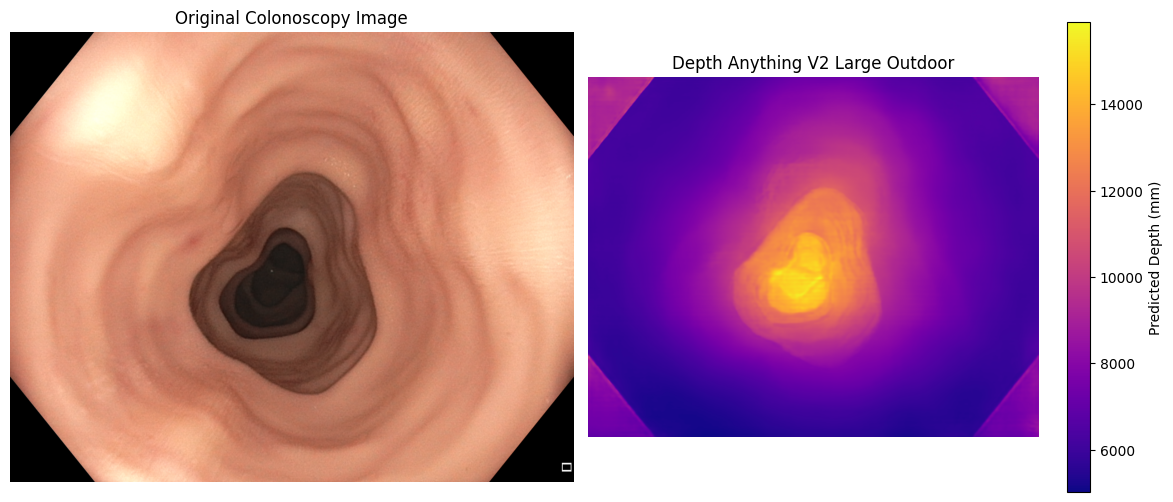

Prediction shape: (1080, 1350)
Minimum depth (mm): 5015.5044
Maximum depth (mm): 15911.468


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch

# Load C3VD development image
image_path = "/content/C3VD/trans_t1_a/trans_t1_a/0001_color.png"

image = cv2.imread(image_path)

if image is None:
    raise FileNotFoundError(image_path)

# Generate Outdoor model prediction
with torch.inference_mode():
    predicted_outdoor = model_outdoor.infer_image(
        image,
        input_size=518
    )

# Convert meters to millimeters
predicted_outdoor_mm = predicted_outdoor * 1000.0

# Display results
rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(rgb)
plt.title("Original Colonoscopy Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(predicted_outdoor_mm, cmap="plasma")
plt.title("Depth Anything V2 Large Outdoor")
plt.colorbar(label="Predicted Depth (mm)")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Prediction shape:", predicted_outdoor_mm.shape)
print("Minimum depth (mm):", predicted_outdoor_mm.min())
print("Maximum depth (mm):", predicted_outdoor_mm.max())

In [ ]:
import os
import cv2
import numpy as np
import torch

from common import CFG, sequence_dir, stream_results_dir

# Development dataset path
dev_folder = str(sequence_dir(CFG, "dev"))

# Output folder
outdoor_dev_output = str(
    stream_results_dir(CFG, "DAv2") / "outdoor" / "dev_predictions"
)

os.makedirs(outdoor_dev_output, exist_ok=True)

# Find all development images
image_files = sorted([
    f for f in os.listdir(dev_folder)
    if f.endswith("_color.png")
])

print("Total development images:", len(image_files))

# Check existing predictions
missing_files = [
    filename
    for filename in image_files
    if not os.path.exists(
        os.path.join(
            outdoor_dev_output,
            filename.replace("_color.png", "_pred.npy")
        )
    )
]

print("Existing predictions:", len(image_files) - len(missing_files))
print("Missing predictions:", len(missing_files))

# Generate only missing predictions
if missing_files:

    if "model_outdoor" not in globals():
        raise RuntimeError(
            "Load model_outdoor before generating predictions."
        )

    model_outdoor.eval()

    for i, filename in enumerate(missing_files, 1):

        image_path = os.path.join(dev_folder, filename)

        image = cv2.imread(image_path)

        if image is None:
            raise FileNotFoundError(image_path)

        with torch.inference_mode():
            prediction = model_outdoor.infer_image(
                image,
                input_size=518
            )

        output_name = filename.replace(
            "_color.png", "_pred.npy"
        )

        # Save raw metric predictions in meters
        np.save(
            os.path.join(outdoor_dev_output, output_name),
            prediction.astype(np.float32)
        )

        if i % 10 == 0 or i == len(missing_files):
            print(f"Processed {i}/{len(missing_files)}")

else:
    print("All local Outdoor development predictions already available!")

print("Large Outdoor development prediction setup completed!")

Total development images: 61
Processed 10/61
Processed 20/61
Processed 30/61
Processed 40/61
Processed 50/61
Processed 60/61
Processed 61/61
All Large Outdoor development predictions saved!


In [ ]:
import os
import cv2
import numpy as np
import torch

from common import CFG, sequence_dir, stream_results_dir

test_folder = str(sequence_dir(CFG, "test"))

outdoor_test_output = str(
    stream_results_dir(CFG, "DAv2") / "outdoor" / "test_predictions"
)

os.makedirs(outdoor_test_output, exist_ok=True)

test_files = sorted([
    f for f in os.listdir(test_folder)
    if f.endswith("_color.png")
])

print("Total test images:", len(test_files))

model_outdoor.eval()

for i, filename in enumerate(test_files):

    image = cv2.imread(
        os.path.join(test_folder, filename)
    )

    if image is None:
        raise RuntimeError(f"Cannot load {filename}")

    with torch.inference_mode():
        prediction = model_outdoor.infer_image(
            image,
            input_size=518
        )

    output_name = filename.replace(
        "_color.png", "_pred.npy"
    )

    # Save raw predictions in meters
    np.save(
        os.path.join(outdoor_test_output, output_name),
        prediction.astype(np.float32)
    )

    if (i + 1) % 10 == 0 or i + 1 == len(test_files):
        print(f"Processed {i + 1}/{len(test_files)}")

print("All Large Outdoor test predictions saved!")

Total test images: 103
Processed 10/103
Processed 20/103
Processed 30/103
Processed 40/103
Processed 50/103
Processed 60/103
Processed 70/103
Processed 80/103
Processed 90/103
Processed 100/103
Processed 103/103
All Large Outdoor test predictions saved!


In [40]:
import numpy as np

# Training-only calibration from Step 51
# train_scale and train_offset are already calculated.

# Four depth intervals for the original smooth correction
train_bins = np.array([0, 20, 40, 60, 100], dtype=np.float64)

train_centers = np.array([10, 30, 50, 80], dtype=np.float64)

print("Training scale:", train_scale)
print("Training offset:", train_offset)
print("Depth bin centers:", train_centers)

Training scale: 13.007499442648554
Training offset: 62.606467056923826
Depth bin centers: [10. 30. 50. 80.]


In [71]:
import os
import cv2
import numpy as np

from common import CFG, sequence_dir, stream_results_dir

dev_folder = str(sequence_dir(CFG, "dev"))
output_folder = str(
    stream_results_dir(CFG, "DAv2") / "small" / "dev_predictions"
)

# Use the same 45 training frames as Step 51
error_sums = np.zeros(len(train_bins) - 1, dtype=np.float64)
pixel_counts = np.zeros(len(train_bins) - 1, dtype=np.int64)

for filename in train_files:

    frame = filename.replace("_pred.npy", "")

    pred = np.load(os.path.join(output_folder, filename))

    gt_raw = cv2.imread(
        os.path.join(dev_folder, f"{frame}_depth.tiff"),
        cv2.IMREAD_UNCHANGED
    )

    rgb = cv2.imread(
        os.path.join(dev_folder, f"{frame}_color.png")
    )

    if gt_raw is None or rgb is None:
        raise FileNotFoundError(frame)

    gt_mm = gt_raw.astype(np.float32) * (100.0 / 65535.0)

    # Mask A
    valid = (
        (gt_raw > 0) &
        (gt_raw < 65535) &
        (rgb.max(axis=2) > 10)
    )

    linear = np.clip(
        -train_scale * pred + train_offset,
        1e-3, 100.0
    )

    signed_error = gt_mm - linear

    for i in range(len(train_bins) - 1):
        low, high = train_bins[i], train_bins[i + 1]

        mask = valid & (linear >= low) & (
            (linear <= high) if i == len(train_bins) - 2
            else (linear < high)
        )

        error_sums[i] += np.sum(
            signed_error[mask], dtype=np.float64
        )
        pixel_counts[i] += np.count_nonzero(mask)

train_corrections = np.divide(
    error_sums,
    pixel_counts,
    out=np.zeros(len(error_sums), dtype=np.float64),
    where=pixel_counts > 0
)

print("TRAINING-ONLY SMOOTH CORRECTION — MASK A")
print("-" * 55)

for i, correction in enumerate(train_corrections):
    print(
        f"{train_bins[i]:.0f}–{train_bins[i+1]:.0f} mm: "
        f"{correction:.4f} mm | Pixels: {pixel_counts[i]}"
    )

print("Training corrections:", train_corrections)

TRAINING-ONLY SMOOTH CORRECTION — MASK A
-------------------------------------------------------
0–20 mm: 1.1255 mm | Pixels: 31207439
20–40 mm: -3.9679 mm | Pixels: 17583593
40–60 mm: 2.8722 mm | Pixels: 10711758
60–100 mm: 22.9926 mm | Pixels: 141877
Training corrections: [ 1.12547775 -3.96791397  2.8721873  22.99256625]


In [42]:
print("Training frames:", len(train_files))
print("Validation frames:", len(val_files))

print("First validation frame:", val_files[0])
print("Last validation frame:", val_files[-1])

print("Correction values:", train_corrections)

assert len(train_files) == 45
assert len(val_files) == 16
assert len(train_corrections) == 4

print("Validation setup verified!")

Training frames: 45
Validation frames: 16
First validation frame: 0045_pred.npy
Last validation frame: 0060_pred.npy
Correction values: [ 1.12547775 -3.96791397  2.8721873  22.99256625]
Validation setup verified!


In [72]:
import numpy as np
import pandas as pd
from common import load_frame, sequence_dir, CFG

records = []

for filename in val_files:
    frame = filename.replace("_pred.npy", "")

    color_path = sequence_dir(CFG, "dev") / f"{frame}_color.png"
    rgb, gt_mm, valid = load_frame(color_path)

    pred = np.load(output_folder / filename) if hasattr(
        output_folder, "__truediv__"
    ) else np.load(os.path.join(output_folder, filename))

    linear = np.clip(
        -train_scale * pred + train_offset,
        1e-3, 100.0
    )

    smooth = np.clip(
        linear + np.interp(
            linear, train_centers, train_corrections
        ),
        1e-3, 100.0
    )

    for name, depth in [("Linear", linear), ("Smooth", smooth)]:
        p = depth[valid]
        g = gt_mm[valid]

        records.append({
            "frame": frame,
            "method": name,
            "mae": np.mean(np.abs(p - g)),
            "absrel": np.mean(np.abs(p - g) / g),
            "mse": np.mean((p - g) ** 2),
            "delta1": np.mean(
                np.maximum(p / g, g / p) < 1.25
            )
        })

df_validation = pd.DataFrame(records)

print("MASK A — 16-FRAME VALIDATION")
print("-" * 65)

for method, df in df_validation.groupby("method"):
    print(
        f"{method:<10} "
        f"MAE={df['mae'].mean():.4f} mm | "
        f"AbsRel={df['absrel'].mean():.4f} | "
        f"RMSE={np.sqrt(df['mse'].mean()):.4f} mm | "
        f"Delta={df['delta1'].mean():.4f}"
    )

MASK A — 16-FRAME VALIDATION
-----------------------------------------------------------------
Linear     MAE=5.2326 mm | AbsRel=0.2791 | RMSE=7.4713 mm | Delta=0.4691
Smooth     MAE=4.3859 mm | AbsRel=0.2417 | RMSE=6.2292 mm | Delta=0.5249


In [44]:
from common import CFG, stream_results_dir

save_dir = stream_results_dir(CFG, "DAv2")

df_validation.to_csv(
    save_dir / "small_smooth_maskA_validation_per_frame.csv",
    index=False
)

print("Validation results saved successfully!")

Validation results saved successfully!
